In [3]:
import numpy as np
import pandas as pd

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from xgboost import XGBClassifier

from lightgbm import LGBMClassifier

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    make_scorer
)

In [5]:
train = pd.read_csv("./train.csv")
test = pd.read_csv("./test.csv")
submission = pd.read_csv("./sample_submission.csv")

print("train shape :", train.shape)
print("test shape :", test.shape)
print("submission shape :", submission.shape)

train.head()

train shape : (381109, 12)
test shape : (127037, 11)
submission shape : (127037, 2)


,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


In [4]:
X = train.drop(columns=["id", "Response"]).copy()
y = train["Response"].copy()

X_test = test.drop(columns=["id"]).copy()

In [5]:
# Vehicle_Damage 변환
damage_map = {
    "No": 0,
    "Yes": 1
}

X["Vehicle_Damage"] = X["Vehicle_Damage"].map(damage_map)
X_test["Vehicle_Damage"] = X_test["Vehicle_Damage"].map(damage_map)


# Gender 변환
gender_map = {
    "Female": 0,
    "Male": 1
}

X["Gender"] = X["Gender"].map(gender_map)
X_test["Gender"] = X_test["Gender"].map(gender_map)

In [6]:
print("Vehicle_Damage")
print(X["Vehicle_Damage"].value_counts())

print("\nGender")
print(X["Gender"].value_counts())

Vehicle_Damage
1    192413
0    188696
Name: Vehicle_Damage, dtype: int64

Gender
1    206089
0    175020
Name: Gender, dtype: int64


In [7]:
categorical_cols = [
    "Region_Code",
    "Vehicle_Age",
    "Policy_Sales_Channel"
]

numeric_cols = [
    "Age",
    "Annual_Premium",
    "Vintage"
]

binary_cols = [
    "Gender",
    "Driving_License",
    "Previously_Insured",
    "Vehicle_Damage"
]

In [8]:
print("범주형 :", categorical_cols)
print("수치형 :", numeric_cols)
print("이진형 :", binary_cols)

범주형 : ['Region_Code', 'Vehicle_Age', 'Policy_Sales_Channel']
수치형 : ['Age', 'Annual_Premium', 'Vintage']
이진형 : ['Gender', 'Driving_License', 'Previously_Insured', 'Vehicle_Damage']


In [9]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train :", X_train.shape)
print("X_valid :", X_valid.shape)

print("\nTrain class ratio")
print(y_train.value_counts(normalize=True))

print("\nValidation class ratio")
print(y_valid.value_counts(normalize=True))

X_train : (304887, 10)
X_valid : (76222, 10)

Train class ratio
0    0.877437
1    0.122563
Name: Response, dtype: float64

Validation class ratio
0    0.877437
1    0.122563
Name: Response, dtype: float64


In [10]:
logistic_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("binary", "passthrough", binary_cols),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    ]
)

In [11]:
tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_cols),
        ("binary", "passthrough", binary_cols),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    ]
)

In [12]:
def pr_auc_metric(y_true, y_prob):
    precision, recall, _ = precision_recall_curve(
        y_true,
        y_prob
    )

    return auc(recall, precision)

In [13]:
pr_auc_scorer = make_scorer(
    pr_auc_metric,
    needs_proba=True
)

In [14]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [15]:
scoring = {
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": pr_auc_scorer
}

In [16]:
logistic_model = Pipeline([
    (
        "preprocessor",
        logistic_preprocessor
    ),

    (
        "model",
        LogisticRegression(
            max_iter=3000,
            random_state=42
        )
    )
])

In [17]:
decision_tree_model = Pipeline([
    (
        "preprocessor",
        tree_preprocessor
    ),

    (
        "model",
        DecisionTreeClassifier(
            random_state=42
        )
    )
])

In [18]:
random_forest_model = Pipeline([
    (
        "preprocessor",
        tree_preprocessor
    ),

    (
        "model",
        RandomForestClassifier(
            random_state=42,
            n_jobs=1
        )
    )
])

In [19]:
gradient_boosting_model = Pipeline([
    (
        "preprocessor",
        tree_preprocessor
    ),

    (
        "model",
        GradientBoostingClassifier(
            random_state=42
        )
    )
])

In [20]:
lightgbm_model = Pipeline([
    (
        "preprocessor",
        tree_preprocessor
    ),

    (
        "model",
        LGBMClassifier(
            objective="binary",
            random_state=42,
            n_jobs=1,
            verbosity=-1
        )
    )
])

In [21]:
baseline_models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model,
    "LightGBM": lightgbm_model
}

In [22]:
baseline_results = []

for name, model in baseline_models.items():

    print("=" * 60)
    print(name)
    print("=" * 60)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    baseline_results.append({
        "Model": name,

        "CV F1":
            scores["test_f1"].mean(),

        "CV ROC-AUC":
            scores["test_roc_auc"].mean(),

        "CV PR-AUC":
            scores["test_pr_auc"].mean()
    })

Logistic Regression
Decision Tree
Random Forest
Gradient Boosting
LightGBM


In [23]:
baseline_df = pd.DataFrame(
    baseline_results
)

baseline_df.sort_values(
    "CV PR-AUC",
    ascending=False
).round(4)

,Model,CV F1,CV ROC-AUC,CV PR-AUC
4,LightGBM,0.0103,0.8571,0.3661
3,Gradient Boosting,0.0004,0.8558,0.3633
1,Decision Tree,0.2975,0.6001,0.3404
0,Logistic Regression,0.0053,0.8491,0.3370
2,Random Forest,0.2055,0.8321,0.3223


In [24]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = (
    negative_count / positive_count
)

print("Negative :", negative_count)
print("Positive :", positive_count)

print(
    "scale_pos_weight :",
    scale_pos_weight
)

Negative : 267519
Positive : 37368
scale_pos_weight : 7.159039820166988


In [ ]:
logistic_tuning_model = Pipeline([
    (
        "preprocessor",
        logistic_preprocessor
    ),

    (
        "model",
        LogisticRegression(
            max_iter=3000,
            random_state=42
        )
    )
])

In [26]:
logistic_params = {

    "model__C": [
        0.001,
        0.003,
        0.01,
        0.03,
        0.1,
        0.3,
        1,
        3,
        10,
        30,
        100
    ],

    "model__class_weight": [
        None,
        "balanced"
    ],

    "model__solver": [
        "liblinear",
        "lbfgs"
    ]
}

In [27]:
decision_tree_tuning_model = Pipeline([
    (
        "preprocessor",
        tree_preprocessor
    ),

    (
        "model",
        DecisionTreeClassifier(
            random_state=42
        )
    )
])

In [28]:
decision_tree_params = {

    "model__criterion": [
        "gini",
        "entropy"
    ],

    "model__max_depth": [
        3, 4, 5, 6,
        8, 10, 12, 15,
        20, 30, None
    ],

    "model__min_samples_split": [
        2, 5, 10,
        20, 50, 100
    ],

    "model__min_samples_leaf": [
        1, 2, 5, 10,
        20, 50, 100
    ],

    "model__max_features": [
        None,
        "sqrt",
        "log2"
    ],

    "model__class_weight": [
        None,
        "balanced"
    ]
}

In [29]:
random_forest_tuning_model = Pipeline([
    (
        "preprocessor",
        tree_preprocessor
    ),

    (
        "model",
        RandomForestClassifier(
            random_state=42,
            n_jobs=1
        )
    )
])

In [30]:
random_forest_params = {

    "model__n_estimators": [
        200,
        300,
        500,
        700,
        1000
    ],

    "model__max_depth": [
        5, 8, 10,
        12, 15, 20,
        30, None
    ],

    "model__min_samples_split": [
        2, 5, 10,
        20, 50
    ],

    "model__min_samples_leaf": [
        1, 2, 4,
        8, 15, 30
    ],

    "model__max_features": [
        "sqrt",
        "log2",
        0.5,
        0.8,
        None
    ],

    "model__bootstrap": [
        True,
        False
    ],

    "model__class_weight": [
        None,
        "balanced",
        "balanced_subsample"
    ]
}

In [31]:
gradient_tuning_model = Pipeline([
    (
        "preprocessor",
        tree_preprocessor
    ),

    (
        "model",
        GradientBoostingClassifier(
            random_state=42
        )
    )
])

In [32]:
gradient_params = {

    "model__n_estimators": [
        100,
        150,
        200,
        300,
        400,
        500
    ],

    "model__learning_rate": [
        0.01,
        0.02,
        0.03,
        0.05,
        0.07,
        0.1
    ],

    "model__max_depth": [
        2, 3, 4,
        5, 6
    ],

    "model__min_samples_split": [
        2, 5, 10,
        20, 50
    ],

    "model__min_samples_leaf": [
        1, 2, 5,
        10, 20
    ],

    "model__subsample": [
        0.6,
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__max_features": [
        None,
        "sqrt",
        "log2"
    ]
}

In [33]:
lightgbm_tuning_model = Pipeline([
    (
        "preprocessor",
        tree_preprocessor
    ),

    (
        "model",
        LGBMClassifier(
            objective="binary",
            random_state=42,
            n_jobs=1,
            verbosity=-1
        )
    )
])

In [34]:
lightgbm_params = {

    "model__n_estimators": [
        100,
        200,
        300,
        500,
        700,
        1000
    ],

    "model__learning_rate": [
        0.005,
        0.01,
        0.02,
        0.03,
        0.05,
        0.07,
        0.1
    ],

    "model__num_leaves": [
        15,
        31,
        47,
        63,
        95,
        127,
        191
    ],

    "model__max_depth": [
        -1,
        4,
        5,
        6,
        8,
        10,
        12,
        15
    ],

    "model__min_child_samples": [
        5,
        10,
        20,
        30,
        50,
        80,
        120
    ],

    "model__subsample": [
        0.6,
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__subsample_freq": [
        1,
        5
    ],

    "model__colsample_bytree": [
        0.6,
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__reg_alpha": [
        0,
        0.01,
        0.1,
        0.5,
        1,
        5
    ],

    "model__reg_lambda": [
        0,
        0.01,
        0.1,
        0.5,
        1,
        5,
        10
    ],

    "model__scale_pos_weight": [
        1.0,
        scale_pos_weight
    ]
}

In [35]:
logistic_search = GridSearchCV(
    estimator=logistic_tuning_model,
    param_grid=logistic_params,
    scoring=scoring,
    refit="pr_auc",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

In [36]:
decision_tree_search = RandomizedSearchCV(
    estimator=decision_tree_tuning_model,
    param_distributions=decision_tree_params,
    n_iter=100,
    scoring=scoring,
    refit="pr_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

In [37]:
random_forest_search = RandomizedSearchCV(
    estimator=random_forest_tuning_model,
    param_distributions=random_forest_params,
    n_iter=80,
    scoring=scoring,
    refit="pr_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

In [38]:
gradient_search = RandomizedSearchCV(
    estimator=gradient_tuning_model,
    param_distributions=gradient_params,
    n_iter=60,
    scoring=scoring,
    refit="pr_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

In [39]:
lightgbm_search = RandomizedSearchCV(
    estimator=lightgbm_tuning_model,
    param_distributions=lightgbm_params,
    n_iter=150,
    scoring=scoring,
    refit="pr_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

In [40]:
logistic_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 44 candidates, totalling 220 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['Age',
                                                                          'Annual_Premium',
                                                                          'Vintage']),
                                                                        ('binary',
                                                                         'passthrough',
                                                                         ['Gender',
                                                                          'Driving_License',
                                                                          'Previously_Ins

In [41]:
best_idx = logistic_search.best_index_

print("Logistic Regression")
print("Best Params :", logistic_search.best_params_)

print(
    "CV F1       :",
    logistic_search.cv_results_[
        "mean_test_f1"
    ][best_idx]
)

print(
    "CV ROC-AUC  :",
    logistic_search.cv_results_[
        "mean_test_roc_auc"
    ][best_idx]
)

print(
    "CV PR-AUC   :",
    logistic_search.cv_results_[
        "mean_test_pr_auc"
    ][best_idx]
)

Logistic Regression
Best Params : {'model__C': 0.03, 'model__class_weight': None, 'model__solver': 'lbfgs'}
CV F1       : 0.0025064270171391394
CV ROC-AUC  : 0.8491586359733787
CV PR-AUC   : 0.33735269920945077


In [42]:
decision_tree_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               'passthrough',
                                                                               ['Age',
                                                                                'Annual_Premium',
                                                                                'Vintage']),
                                                                              ('binary',
                                                                               'passthrough',
                                                                               ['Gender',
                                                                                'Driving_License',
                          

In [43]:
best_idx = decision_tree_search.best_index_

print("Decision Tree")
print("Best Params :", decision_tree_search.best_params_)

print(
    "CV F1       :",
    decision_tree_search.cv_results_[
        "mean_test_f1"
    ][best_idx]
)

print(
    "CV ROC-AUC  :",
    decision_tree_search.cv_results_[
        "mean_test_roc_auc"
    ][best_idx]
)

print(
    "CV PR-AUC   :",
    decision_tree_search.cv_results_[
        "mean_test_pr_auc"
    ][best_idx]
)

Decision Tree
Best Params : {'model__min_samples_split': 100, 'model__min_samples_leaf': 5, 'model__max_features': None, 'model__max_depth': 4, 'model__criterion': 'gini', 'model__class_weight': 'balanced'}
CV F1       : 0.4077818737095953
CV ROC-AUC  : 0.8315155949762787
CV PR-AUC   : 0.5742302360349157


In [44]:
random_forest_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 80 candidates, totalling 400 fits


/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               'passthrough',
                                                                               ['Age',
                                                                                'Annual_Premium',
                                                                                'Vintage']),
                                                                              ('binary',
                                                                               'passthrough',
                                                                               ['Gender',
                                                                                'Driving_License',
                          

In [46]:
import numpy as np

print("Best Params:")
print(random_forest_search.best_params_)

print("\nBest PR-AUC:")
print(random_forest_search.best_score_)

print(
    "\n실패한 후보 수:",
    np.isnan(
        random_forest_search.cv_results_["mean_test_pr_auc"]
    ).sum()
)

Best Params:
{'model__n_estimators': 200, 'model__min_samples_split': 20, 'model__min_samples_leaf': 30, 'model__max_features': None, 'model__max_depth': 5, 'model__class_weight': 'balanced_subsample', 'model__bootstrap': False}

Best PR-AUC:
0.5691743845490357

실패한 후보 수: 0


In [45]:
best_idx = random_forest_search.best_index_

print("Random Forest")
print("Best Params :", random_forest_search.best_params_)

print(
    "CV F1       :",
    random_forest_search.cv_results_[
        "mean_test_f1"
    ][best_idx]
)

print(
    "CV ROC-AUC  :",
    random_forest_search.cv_results_[
        "mean_test_roc_auc"
    ][best_idx]
)

print(
    "CV PR-AUC   :",
    random_forest_search.cv_results_[
        "mean_test_pr_auc"
    ][best_idx]
)

Random Forest
Best Params : {'model__n_estimators': 200, 'model__min_samples_split': 20, 'model__min_samples_leaf': 30, 'model__max_features': None, 'model__max_depth': 5, 'model__class_weight': 'balanced_subsample', 'model__bootstrap': False}
CV F1       : 0.42564350365009335
CV ROC-AUC  : 0.8366227930328227
CV PR-AUC   : 0.5691743845490357


In [47]:
gradient_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 60 candidates, totalling 300 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               'passthrough',
                                                                               ['Age',
                                                                                'Annual_Premium',
                                                                                'Vintage']),
                                                                              ('binary',
                                                                               'passthrough',
                                                                               ['Gender',
                                                                                'Driving_License',
                          

In [48]:
best_idx = gradient_search.best_index_

print("Gradient Boosting")
print("Best Params :", gradient_search.best_params_)

print(
    "CV F1       :",
    gradient_search.cv_results_[
        "mean_test_f1"
    ][best_idx]
)

print(
    "CV ROC-AUC  :",
    gradient_search.cv_results_[
        "mean_test_roc_auc"
    ][best_idx]
)

print(
    "CV PR-AUC   :",
    gradient_search.cv_results_[
        "mean_test_pr_auc"
    ][best_idx]
)

Gradient Boosting
Best Params : {'model__subsample': 0.6, 'model__n_estimators': 400, 'model__min_samples_split': 50, 'model__min_samples_leaf': 10, 'model__max_features': None, 'model__max_depth': 5, 'model__learning_rate': 0.05}
CV F1       : 0.030749862169333876
CV ROC-AUC  : 0.8577427970987561
CV PR-AUC   : 0.37015184424353303


In [49]:
lightgbm_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               'passthrough',
                                                                               ['Age',
                                                                                'Annual_Premium',
                                                                                'Vintage']),
                                                                              ('binary',
                                                                               'passthrough',
                                                                               ['Gender',
                                                                                'Driving_License',
                          

In [50]:
best_idx = lightgbm_search.best_index_

print("LightGBM")
print("Best Params :", lightgbm_search.best_params_)

print(
    "CV F1       :",
    lightgbm_search.cv_results_[
        "mean_test_f1"
    ][best_idx]
)

print(
    "CV ROC-AUC  :",
    lightgbm_search.cv_results_[
        "mean_test_roc_auc"
    ][best_idx]
)

print(
    "CV PR-AUC   :",
    lightgbm_search.cv_results_[
        "mean_test_pr_auc"
    ][best_idx]
)

LightGBM
Best Params : {'model__subsample_freq': 5, 'model__subsample': 0.9, 'model__scale_pos_weight': 7.159039820166988, 'model__reg_lambda': 0.1, 'model__reg_alpha': 1, 'model__num_leaves': 15, 'model__n_estimators': 100, 'model__min_child_samples': 10, 'model__max_depth': 5, 'model__learning_rate': 0.005, 'model__colsample_bytree': 1.0}
CV F1       : 0.0
CV ROC-AUC  : 0.8473251461516658
CV PR-AUC   : 0.3930414335028533


In [52]:
# XGBoost 모델 안만들어서 추가 제작

xgboost_tuning_model = Pipeline([
    (
        "preprocessor",
        tree_preprocessor
    ),

    (
        "model",
        XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=42,
            n_jobs=1
        )
    )
])

In [53]:
xgboost_params = {

    "model__n_estimators": [
        100, 200, 300,
        500, 700, 1000
    ],

    "model__learning_rate": [
        0.005,
        0.01,
        0.02,
        0.03,
        0.05,
        0.07,
        0.1
    ],

    "model__max_depth": [
        3, 4, 5,
        6, 8, 10
    ],

    "model__min_child_weight": [
        1, 3, 5,
        10, 20
    ],

    "model__gamma": [
        0,
        0.01,
        0.1,
        0.3,
        1
    ],

    "model__subsample": [
        0.6,
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__colsample_bytree": [
        0.6,
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__reg_alpha": [
        0,
        0.01,
        0.1,
        0.5,
        1,
        5
    ],

    "model__reg_lambda": [
        0.1,
        0.5,
        1,
        5,
        10
    ],

    "model__scale_pos_weight": [
        1.0,
        scale_pos_weight
    ]
}

In [54]:
xgb_scoring = {
    "f1": "f1",
    "roc_auc": "roc_auc",
    "ap": "average_precision"
}

In [55]:
xgboost_search = RandomizedSearchCV(
    estimator=xgboost_tuning_model,
    param_distributions=xgboost_params,
    n_iter=150,
    scoring=xgb_scoring,
    refit="ap",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

In [56]:
xgboost_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               'passthrough',
                                                                               ['Age',
                                                                                'Annual_Premium',
                                                                                'Vintage']),
                                                                              ('binary',
                                                                               'passthrough',
                                                                               ['Gender',
                                                                                'Driving_License',
                          

In [57]:
best_idx = xgboost_search.best_index_

print("XGBoost")

print(
    "Best Params :",
    xgboost_search.best_params_
)

print(
    "CV F1       :",
    xgboost_search.cv_results_[
        "mean_test_f1"
    ][best_idx]
)

print(
    "CV ROC-AUC  :",
    xgboost_search.cv_results_[
        "mean_test_roc_auc"
    ][best_idx]
)

print(
    "CV AP       :",
    xgboost_search.cv_results_[
        "mean_test_ap"
    ][best_idx]
)

XGBoost
Best Params : {'model__subsample': 0.9, 'model__scale_pos_weight': 1.0, 'model__reg_lambda': 10, 'model__reg_alpha': 0.5, 'model__n_estimators': 500, 'model__min_child_weight': 20, 'model__max_depth': 6, 'model__learning_rate': 0.05, 'model__gamma': 0.1, 'model__colsample_bytree': 0.6}
CV F1       : 0.02880104957375538
CV ROC-AUC  : 0.8582262085521375
CV AP       : 0.3717019380983766


In [61]:
best_models = {
    "Logistic Regression": logistic_search.best_estimator_,
    "Decision Tree": decision_tree_search.best_estimator_,
    "Random Forest": random_forest_search.best_estimator_,
    "Gradient Boosting": gradient_search.best_estimator_,
    "LightGBM": lightgbm_search.best_estimator_,
    "XGBoost": xgboost_search.best_estimator_
}

In [62]:
from sklearn.model_selection import cross_validate

ap_scoring = {
    "f1": "f1",
    "roc_auc": "roc_auc",
    "ap": "average_precision"
}

ap_results = []

for name, model in best_models.items():

    print(f"{name} AP 재평가 중...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=ap_scoring,
        n_jobs=-1
    )

    ap_results.append({
        "Model": name,
        "CV F1 @ 0.5": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
        "CV AP": scores["test_ap"].mean()
    })

    print(f"{name} 완료\n")

Logistic Regression AP 재평가 중...
Logistic Regression 완료

Decision Tree AP 재평가 중...
Decision Tree 완료

Random Forest AP 재평가 중...
Random Forest 완료

Gradient Boosting AP 재평가 중...
Gradient Boosting 완료

LightGBM AP 재평가 중...
LightGBM 완료

XGBoost AP 재평가 중...
XGBoost 완료



In [63]:
ap_results_df = pd.DataFrame(ap_results)

ap_results_df.sort_values(
    by="CV AP",
    ascending=False
).round(4)

,Model,CV F1 @ 0.5,CV ROC-AUC,CV AP
5,XGBoost,0.0288,0.8582,0.3717
3,Gradient Boosting,0.0307,0.8577,0.3703
0,Logistic Regression,0.0025,0.8492,0.3375
4,LightGBM,0.0000,0.8473,0.3330
2,Random Forest,0.4256,0.8366,0.3067
1,Decision Tree,0.4078,0.8315,0.2981


In [66]:
gradient_ap_scoring = {
    "f1": "f1",
    "roc_auc": "roc_auc",
    "ap": "average_precision"
}

gradient_ap_search = RandomizedSearchCV(
    estimator=gradient_tuning_model,
    param_distributions=gradient_params,
    n_iter=50, 
    scoring=gradient_ap_scoring,
    refit="ap",
    cv=StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    ),
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

In [67]:
gradient_ap_search.fit(
    X_train,
    y_train
)

Fitting 3 folds for each of 50 candidates, totalling 150 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               'passthrough',
                                                                               ['Age',
                                                                                'Annual_Premium',
                                                                                'Vintage']),
                                                                              ('binary',
                                                                               'passthrough',
                                                                               ['Gender',
                                                                                'Driving_License',
                          

In [68]:
best_idx = gradient_ap_search.best_index_

print("Gradient Boosting - AP Tuning")
print("Best Params :", gradient_ap_search.best_params_)

print(
    "CV F1 @ 0.5 :",
    gradient_ap_search.cv_results_[
        "mean_test_f1"
    ][best_idx]
)

print(
    "CV ROC-AUC  :",
    gradient_ap_search.cv_results_[
        "mean_test_roc_auc"
    ][best_idx]
)

print(
    "CV AP       :",
    gradient_ap_search.cv_results_[
        "mean_test_ap"
    ][best_idx]
)

Gradient Boosting - AP Tuning
Best Params : {'model__subsample': 0.6, 'model__n_estimators': 400, 'model__min_samples_split': 50, 'model__min_samples_leaf': 10, 'model__max_features': None, 'model__max_depth': 5, 'model__learning_rate': 0.05}
CV F1 @ 0.5 : 0.03258713073403191
CV ROC-AUC  : 0.8575747351223257
CV AP       : 0.3682997203084892


In [69]:
best_gradient = gradient_ap_search.best_estimator_

gradient_final_scores = cross_validate(
    best_gradient,
    X_train,
    y_train,
    cv=cv,  # 기존 5-Fold StratifiedKFold
    scoring={
        "f1": "f1",
        "roc_auc": "roc_auc",
        "ap": "average_precision"
    },
    n_jobs=-1
)

print("Gradient Boosting - Final 5-Fold")
print("CV F1 @ 0.5 :", gradient_final_scores["test_f1"].mean())
print("CV ROC-AUC  :", gradient_final_scores["test_roc_auc"].mean())
print("CV AP       :", gradient_final_scores["test_ap"].mean())

Gradient Boosting - Final 5-Fold
CV F1 @ 0.5 : 0.030749862169333876
CV ROC-AUC  : 0.8577427970987561
CV AP       : 0.3703085707052303


In [70]:
lightgbm_ap_scoring = {
    "f1": "f1",
    "roc_auc": "roc_auc",
    "ap": "average_precision"
}

lightgbm_ap_search = RandomizedSearchCV(
    estimator=lightgbm_tuning_model,
    param_distributions=lightgbm_params,
    n_iter=50,
    scoring=lightgbm_ap_scoring,
    refit="ap",
    cv=StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    ),
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

lightgbm_ap_search.fit(
    X_train,
    y_train
)

Fitting 3 folds for each of 50 candidates, totalling 150 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               'passthrough',
                                                                               ['Age',
                                                                                'Annual_Premium',
                                                                                'Vintage']),
                                                                              ('binary',
                                                                               'passthrough',
                                                                               ['Gender',
                                                                                'Driving_License',
                          

In [71]:
best_idx = lightgbm_ap_search.best_index_

print("LightGBM - AP Tuning")
print("Best Params :", lightgbm_ap_search.best_params_)
print(
    "CV F1 @ 0.5 :",
    lightgbm_ap_search.cv_results_["mean_test_f1"][best_idx]
)
print(
    "CV ROC-AUC  :",
    lightgbm_ap_search.cv_results_["mean_test_roc_auc"][best_idx]
)
print(
    "CV AP       :",
    lightgbm_ap_search.cv_results_["mean_test_ap"][best_idx]
)

LightGBM - AP Tuning
Best Params : {'model__subsample_freq': 5, 'model__subsample': 0.9, 'model__scale_pos_weight': 7.159039820166988, 'model__reg_lambda': 0, 'model__reg_alpha': 0.01, 'model__num_leaves': 127, 'model__n_estimators': 1000, 'model__min_child_samples': 50, 'model__max_depth': 10, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.6}
CV F1 @ 0.5 : 0.4382554705413341
CV ROC-AUC  : 0.8575096920828557
CV AP       : 0.36941013209709955


In [72]:
best_lightgbm = lightgbm_ap_search.best_estimator_

lightgbm_final_scores = cross_validate(
    best_lightgbm,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "f1": "f1",
        "roc_auc": "roc_auc",
        "ap": "average_precision"
    },
    n_jobs=-1
)

print("LightGBM - Final 5-Fold")
print(
    "CV F1 @ 0.5 :",
    lightgbm_final_scores["test_f1"].mean()
)
print(
    "CV ROC-AUC  :",
    lightgbm_final_scores["test_roc_auc"].mean()
)
print(
    "CV AP       :",
    lightgbm_final_scores["test_ap"].mean()
)

LightGBM - Final 5-Fold
CV F1 @ 0.5 : 0.43849957953164775
CV ROC-AUC  : 0.8580108365231386
CV AP       : 0.37146819512436025


In [73]:
top_models = {
    "XGBoost": xgboost_search.best_estimator_,
    "Gradient Boosting": gradient_ap_search.best_estimator_,
    "LightGBM": lightgbm_ap_search.best_estimator_
}

In [74]:
from sklearn.model_selection import cross_val_predict

In [75]:
oof_probabilities = {}

for name, model in top_models.items():

    print(f"{name} OOF 예측 시작")

    oof_prob = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    oof_probabilities[name] = oof_prob

    print(f"{name} OOF 예측 완료\n")

XGBoost OOF 예측 시작
XGBoost OOF 예측 완료

Gradient Boosting OOF 예측 시작
Gradient Boosting OOF 예측 완료

LightGBM OOF 예측 시작
LightGBM OOF 예측 완료



In [76]:
from sklearn.metrics import (
    precision_recall_curve,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)

def find_best_threshold(y_true, y_prob):

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        y_prob
    )

    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-10)
    )

    best_idx = np.argmax(f1_scores)

    best_threshold = thresholds[best_idx]

    y_pred = (
        y_prob >= best_threshold
    ).astype(int)

    return {
        "Best Threshold": best_threshold,
        "F1": f1_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "AP": average_precision_score(y_true, y_prob)
    }

In [77]:
oof_results = []

for name, y_prob in oof_probabilities.items():

    result = find_best_threshold(
        y_train,
        y_prob
    )

    result["Model"] = name

    oof_results.append(result)

oof_results_df = pd.DataFrame(
    oof_results
)

oof_results_df = oof_results_df[
    [
        "Model",
        "Best Threshold",
        "F1",
        "Precision",
        "Recall",
        "ROC-AUC",
        "AP"
    ]
]

oof_results_df.sort_values(
    "F1",
    ascending=False
).round(4)

,Model,Best Threshold,F1,Precision,Recall,ROC-AUC,AP
0,XGBoost,0.2285,0.4592,0.3299,0.7555,0.8582,0.3714
2,LightGBM,0.6756,0.4592,0.3306,0.7515,0.8580,0.3711
1,Gradient Boosting,0.2215,0.4590,0.3285,0.7614,0.8577,0.3699


In [78]:
best_thresholds = (
    oof_results_df
    .set_index("Model")["Best Threshold"]
    .to_dict()
)

best_thresholds

{'XGBoost': 0.22849713265895844,
 'Gradient Boosting': 0.22145308220262716,
 'LightGBM': 0.6756276170283404}

In [79]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

validation_results = []

for name, model in top_models.items():

    # Validation 확률 예측
    y_prob = model.predict_proba(X_valid)[:, 1]

    # OOF에서 이미 결정한 threshold
    threshold = best_thresholds[name]

    # 최종 분류
    y_pred = (
        y_prob >= threshold
    ).astype(int)

    validation_results.append({
        "Model": name,
        "Threshold": threshold,
        "F1": f1_score(y_valid, y_pred),
        "Precision": precision_score(
            y_valid,
            y_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_valid,
            y_pred,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_valid,
            y_prob
        ),
        "AP": average_precision_score(
            y_valid,
            y_prob
        )
    })

In [80]:
validation_df = pd.DataFrame(
    validation_results
)

validation_df.sort_values(
    by="F1",
    ascending=False
).round(4)

,Model,Threshold,F1,Precision,Recall,ROC-AUC,AP
0,XGBoost,0.2285,0.4605,0.3310,0.7568,0.8587,0.3717
1,Gradient Boosting,0.2215,0.4604,0.3295,0.7638,0.8583,0.3712
2,LightGBM,0.6756,0.4583,0.3298,0.7505,0.8584,0.3710


In [81]:
import numpy as np

from sklearn.metrics import (
    precision_recall_curve,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)

def find_best_f1_threshold(y_true, y_prob):

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        y_prob
    )

    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-10)
    )

    best_idx = np.argmax(f1_scores)

    return thresholds[best_idx]

In [82]:
from sklearn.model_selection import (
    StratifiedKFold,
    RandomizedSearchCV,
    cross_val_predict
)

from sklearn.base import clone

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [83]:
xgb_fine_params = {

    "model__n_estimators": [
        350, 400, 500, 600, 700
    ],

    "model__learning_rate": [
        0.03, 0.04, 0.05, 0.06, 0.07
    ],

    "model__max_depth": [
        4, 5, 6, 7, 8
    ],

    "model__min_child_weight": [
        10, 15, 20, 30, 40
    ],

    "model__gamma": [
        0, 0.05, 0.1, 0.2, 0.3
    ],

    "model__subsample": [
        0.8, 0.85, 0.9, 0.95, 1.0
    ],

    "model__colsample_bytree": [
        0.4, 0.5, 0.6, 0.7, 0.8
    ],

    "model__reg_alpha": [
        0.1, 0.3, 0.5, 0.7, 1.0
    ],

    "model__reg_lambda": [
        5, 10, 15, 20, 30
    ],

    # 기존 탐색에서 AP 기준 최적값이 1.0이었으므로 고정
    "model__scale_pos_weight": [
        1.0
    ]
}

In [84]:
current_xgb = xgboost_search.best_estimator_

baseline_nested_prob = np.zeros(len(X_train))
baseline_nested_pred = np.zeros(len(X_train), dtype=int)

baseline_fold_results = []

for fold, (train_idx, valid_idx) in enumerate(
    outer_cv.split(X_train, y_train),
    start=1
):

    print(f"===== Baseline XGBoost Fold {fold} =====")

    X_inner_train = X_train.iloc[train_idx]
    X_outer_valid = X_train.iloc[valid_idx]

    y_inner_train = y_train.iloc[train_idx]
    y_outer_valid = y_train.iloc[valid_idx]

    model = clone(current_xgb)

    # Inner OOF 확률 → threshold 결정
    inner_prob = cross_val_predict(
        model,
        X_inner_train,
        y_inner_train,
        cv=inner_cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    threshold = find_best_f1_threshold(
        y_inner_train,
        inner_prob
    )

    # Outer train 전체로 학습
    model.fit(
        X_inner_train,
        y_inner_train
    )

    # Outer validation 예측
    outer_prob = model.predict_proba(
        X_outer_valid
    )[:, 1]

    outer_pred = (
        outer_prob >= threshold
    ).astype(int)

    baseline_nested_prob[valid_idx] = outer_prob
    baseline_nested_pred[valid_idx] = outer_pred

    baseline_fold_results.append({
        "Fold": fold,
        "Threshold": threshold,
        "F1": f1_score(
            y_outer_valid,
            outer_pred
        ),
        "ROC-AUC": roc_auc_score(
            y_outer_valid,
            outer_prob
        ),
        "AP": average_precision_score(
            y_outer_valid,
            outer_prob
        )
    })

===== Baseline XGBoost Fold 1 =====
===== Baseline XGBoost Fold 2 =====
===== Baseline XGBoost Fold 3 =====
===== Baseline XGBoost Fold 4 =====
===== Baseline XGBoost Fold 5 =====


In [85]:
baseline_nested_df = pd.DataFrame(
    baseline_fold_results
)

baseline_nested_df

,Fold,Threshold,F1,ROC-AUC,AP
0,1,0.220307,0.460549,0.859688,0.374888
1,2,0.238248,0.460470,0.859896,0.373282
2,3,0.223286,0.458372,0.858793,0.373333
3,4,0.226300,0.459320,0.857328,0.368279
4,5,0.224060,0.452955,0.855426,0.368727


In [86]:
print("===== Current XGBoost Nested CV =====")

print(
    "F1        :",
    f1_score(
        y_train,
        baseline_nested_pred
    )
)

print(
    "Precision :",
    precision_score(
        y_train,
        baseline_nested_pred
    )
)

print(
    "Recall    :",
    recall_score(
        y_train,
        baseline_nested_pred
    )
)

print(
    "ROC-AUC   :",
    roc_auc_score(
        y_train,
        baseline_nested_prob
    )
)

print(
    "AP        :",
    average_precision_score(
        y_train,
        baseline_nested_prob
    )
)

===== Current XGBoost Nested CV =====
F1        : 0.4583090756193803
Precision : 0.32837411939191696
Recall    : 0.7584029115821024
ROC-AUC   : 0.8582029339694421
AP        : 0.37137243582063845


In [88]:
fine_nested_prob = np.zeros(len(X_train))
fine_nested_pred = np.zeros(len(X_train), dtype=int)

fine_fold_results = []
fine_best_params = []

for fold, (train_idx, valid_idx) in enumerate(
    outer_cv.split(X_train, y_train),
    start=1
):

    print("=" * 70)
    print(f"Fine XGBoost Outer Fold {fold}")
    print("=" * 70)

    X_inner_train = X_train.iloc[train_idx]
    X_outer_valid = X_train.iloc[valid_idx]

    y_inner_train = y_train.iloc[train_idx]
    y_outer_valid = y_train.iloc[valid_idx]

    # -----------------------------
    # 1. Inner CV 하이퍼파라미터 탐색
    # -----------------------------

    search = RandomizedSearchCV(
        estimator=clone(
            xgboost_tuning_model
        ),
        param_distributions=xgb_fine_params,

        # Outer Fold마다 30개 후보
        n_iter=30,

        scoring={
            "roc_auc": "roc_auc",
            "ap": "average_precision"
        },

        refit="ap",

        cv=inner_cv,

        random_state=42,

        n_jobs=-1,

        verbose=1,

        return_train_score=False
    )

    search.fit(
        X_inner_train,
        y_inner_train
    )

    best_model = search.best_estimator_

    fine_best_params.append(
        search.best_params_
    )

    # -----------------------------
    # 2. Inner OOF로 threshold 결정
    # -----------------------------

    inner_prob = cross_val_predict(
        clone(best_model),
        X_inner_train,
        y_inner_train,
        cv=inner_cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    threshold = find_best_f1_threshold(
        y_inner_train,
        inner_prob
    )

    # -----------------------------
    # 3. Outer Validation
    # -----------------------------

    outer_prob = best_model.predict_proba(
        X_outer_valid
    )[:, 1]

    outer_pred = (
        outer_prob >= threshold
    ).astype(int)

    fine_nested_prob[valid_idx] = outer_prob
    fine_nested_pred[valid_idx] = outer_pred

    fold_result = {

        "Fold": fold,

        "Threshold":
            threshold,

        "F1":
            f1_score(
                y_outer_valid,
                outer_pred
            ),

        "Precision":
            precision_score(
                y_outer_valid,
                outer_pred
            ),

        "Recall":
            recall_score(
                y_outer_valid,
                outer_pred
            ),

        "ROC-AUC":
            roc_auc_score(
                y_outer_valid,
                outer_prob
            ),

        "AP":
            average_precision_score(
                y_outer_valid,
                outer_prob
            )
    }

    fine_fold_results.append(
        fold_result
    )

    print(fold_result)

Fine XGBoost Outer Fold 1
Fitting 3 folds for each of 30 candidates, totalling 90 fits
{'Fold': 1, 'Threshold': 0.2239532, 'F1': 0.46262554086777025, 'Precision': 0.3288931534684202, 'Recall': 0.7796360717152796, 'ROC-AUC': 0.8596259547051791, 'AP': 0.3747729173417865}
Fine XGBoost Outer Fold 2
Fitting 3 folds for each of 30 candidates, totalling 90 fits
{'Fold': 2, 'Threshold': 0.23233573, 'F1': 0.4626902107575881, 'Precision': 0.33243685687558466, 'Recall': 0.7607706716617608, 'ROC-AUC': 0.859381975687567, 'AP': 0.3703120805256801}
Fine XGBoost Outer Fold 3
Fitting 3 folds for each of 30 candidates, totalling 90 fits
{'Fold': 3, 'Threshold': 0.22117232, 'F1': 0.4583102821465265, 'Precision': 0.32518364829249147, 'Recall': 0.7759935768767563, 'ROC-AUC': 0.8585880511548112, 'AP': 0.3736594667778837}
Fine XGBoost Outer Fold 4
Fitting 3 folds for each of 30 candidates, totalling 90 fits
{'Fold': 4, 'Threshold': 0.22549066, 'F1': 0.459475978973962, 'Precision': 0.3303257558003281, 'Recall

In [89]:
fine_nested_df = pd.DataFrame(
    fine_fold_results
)

fine_nested_df

,Fold,Threshold,F1,Precision,Recall,ROC-AUC,AP
0,1,0.223953,0.462626,0.328893,0.779636,0.859626,0.374773
1,2,0.232336,0.462690,0.332437,0.760771,0.859382,0.370312
2,3,0.221172,0.458310,0.325184,0.775994,0.858588,0.373659
3,4,0.225491,0.459476,0.330326,0.754449,0.857246,0.367738
4,5,0.224783,0.453428,0.322668,0.762376,0.855468,0.368341


In [90]:
print("===== Fine Tuned XGBoost Nested CV =====")

print(
    "F1        :",
    f1_score(
        y_train,
        fine_nested_pred
    )
)

print(
    "Precision :",
    precision_score(
        y_train,
        fine_nested_pred
    )
)

print(
    "Recall    :",
    recall_score(
        y_train,
        fine_nested_pred
    )
)

print(
    "ROC-AUC   :",
    roc_auc_score(
        y_train,
        fine_nested_prob
    )
)

print(
    "AP        :",
    average_precision_score(
        y_train,
        fine_nested_prob
    )
)

===== Fine Tuned XGBoost Nested CV =====
F1        : 0.45929025483170205
Precision : 0.32785159245144824
Recall    : 0.7666452579747377
ROC-AUC   : 0.8580324482065753
AP        : 0.37064012557537407


In [91]:
ensemble_models = {
    "XGBoost": xgboost_search.best_estimator_,
    "Gradient Boosting": gradient_ap_search.best_estimator_,
    "LightGBM": lightgbm_ap_search.best_estimator_
}

In [92]:
from sklearn.model_selection import cross_val_predict

ensemble_oof_probs = {}

for name, model in ensemble_models.items():

    print(f"{name} OOF 예측 시작")

    prob = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    ensemble_oof_probs[name] = prob

    print(f"{name} 완료")

XGBoost OOF 예측 시작
XGBoost 완료
Gradient Boosting OOF 예측 시작
Gradient Boosting 완료
LightGBM OOF 예측 시작
LightGBM 완료


In [93]:
ensemble_oof_prob = (
    ensemble_oof_probs["XGBoost"]
    + ensemble_oof_probs["Gradient Boosting"]
    + ensemble_oof_probs["LightGBM"]
) / 3

In [94]:
ensemble_result = find_best_threshold(
    y_train,
    ensemble_oof_prob
)

ensemble_result

{'Best Threshold': 0.3778295294866365,
 'F1': 0.45979703996134097,
 'Precision': 0.3312953673650044,
 'Recall': 0.7511507171911797,
 'ROC-AUC': 0.8584149274874402,
 'AP': 0.372051058197749}

In [95]:
print("===== Soft Voting Ensemble OOF =====")

print(
    "Best Threshold :",
    ensemble_result["Best Threshold"]
)

print(
    "F1             :",
    ensemble_result["F1"]
)

print(
    "Precision      :",
    ensemble_result["Precision"]
)

print(
    "Recall         :",
    ensemble_result["Recall"]
)

print(
    "ROC-AUC        :",
    ensemble_result["ROC-AUC"]
)

print(
    "AP             :",
    ensemble_result["AP"]
)

===== Soft Voting Ensemble OOF =====
Best Threshold : 0.3778295294866365
F1             : 0.45979703996134097
Precision      : 0.3312953673650044
Recall         : 0.7511507171911797
ROC-AUC        : 0.8584149274874402
AP             : 0.372051058197749


In [96]:
ensemble_comparison = oof_results_df.copy()

ensemble_row = pd.DataFrame([{
    "Model": "Soft Voting",
    "Best Threshold": ensemble_result["Best Threshold"],
    "F1": ensemble_result["F1"],
    "Precision": ensemble_result["Precision"],
    "Recall": ensemble_result["Recall"],
    "ROC-AUC": ensemble_result["ROC-AUC"],
    "AP": ensemble_result["AP"]
}])

ensemble_comparison = pd.concat(
    [
        ensemble_comparison,
        ensemble_row
    ],
    ignore_index=True
)

ensemble_comparison.sort_values(
    by="F1",
    ascending=False
).round(4)

,Model,Best Threshold,F1,Precision,Recall,ROC-AUC,AP
3,Soft Voting,0.3778,0.4598,0.3313,0.7512,0.8584,0.3721
0,XGBoost,0.2285,0.4592,0.3299,0.7555,0.8582,0.3714
2,LightGBM,0.6756,0.4592,0.3306,0.7515,0.8580,0.3711
1,Gradient Boosting,0.2215,0.4590,0.3285,0.7614,0.8577,0.3699


In [97]:
ensemble_threshold = 0.3778295294866365

# 각 모델의 Validation 확률
xgb_valid_prob = ensemble_models[
    "XGBoost"
].predict_proba(X_valid)[:, 1]

gb_valid_prob = ensemble_models[
    "Gradient Boosting"
].predict_proba(X_valid)[:, 1]

lgbm_valid_prob = ensemble_models[
    "LightGBM"
].predict_proba(X_valid)[:, 1]


# 세 모델 확률 평균
ensemble_valid_prob = (
    xgb_valid_prob
    + gb_valid_prob
    + lgbm_valid_prob
) / 3


# OOF에서 결정한 threshold 적용
ensemble_valid_pred = (
    ensemble_valid_prob >= ensemble_threshold
).astype(int)

In [98]:
print("===== Soft Voting Validation =====")

print(
    "Threshold :",
    ensemble_threshold
)

print(
    "F1        :",
    f1_score(
        y_valid,
        ensemble_valid_pred
    )
)

print(
    "Precision :",
    precision_score(
        y_valid,
        ensemble_valid_pred
    )
)

print(
    "Recall    :",
    recall_score(
        y_valid,
        ensemble_valid_pred
    )
)

print(
    "ROC-AUC   :",
    roc_auc_score(
        y_valid,
        ensemble_valid_prob
    )
)

print(
    "AP        :",
    average_precision_score(
        y_valid,
        ensemble_valid_prob
    )
)

===== Soft Voting Validation =====
Threshold : 0.3778295294866365
F1        : 0.45974978712255193
Precision : 0.3312098905247263
Recall    : 0.7513380432455578
ROC-AUC   : 0.8588168943196799
AP        : 0.372468640199521


In [99]:
# ============================================================
# 초기 XGBoost vs 최종 XGBoost 성능 비교
# ============================================================

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)

# ------------------------------------------------------------
# 1. 초기 XGBoost
#    - 하이퍼파라미터 튜닝 전
#    - 기본 threshold = 0.5
# ------------------------------------------------------------

initial_xgb = Pipeline([
    ("preprocessor", tree_preprocessor),

    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

initial_xgb.fit(
    X_train,
    y_train
)

initial_prob = initial_xgb.predict_proba(
    X_valid
)[:, 1]

initial_pred = (
    initial_prob >= 0.5
).astype(int)


# ------------------------------------------------------------
# 2. 튜닝된 XGBoost
#    - 최종 하이퍼파라미터
#    - threshold는 아직 기본값 0.5
# ------------------------------------------------------------

final_model = xgboost_search.best_estimator_

final_prob = final_model.predict_proba(
    X_valid
)[:, 1]

final_pred_05 = (
    final_prob >= 0.5
).astype(int)


# ------------------------------------------------------------
# 3. 최종 XGBoost
#    - 최종 하이퍼파라미터
#    - OOF에서 결정한 최적 threshold
# ------------------------------------------------------------

final_threshold = best_thresholds["XGBoost"]

final_pred_opt = (
    final_prob >= final_threshold
).astype(int)


# ------------------------------------------------------------
# 평가 함수
# ------------------------------------------------------------

def evaluate_xgb(name, y_prob, y_pred, threshold):

    return {
        "Model": name,
        "Threshold": threshold,

        "F1": f1_score(
            y_valid,
            y_pred
        ),

        "Precision": precision_score(
            y_valid,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_valid,
            y_pred,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_valid,
            y_prob
        ),

        "AP": average_precision_score(
            y_valid,
            y_prob
        )
    }


# ------------------------------------------------------------
# 비교 결과
# ------------------------------------------------------------

xgb_comparison = pd.DataFrame([

    evaluate_xgb(
        "Initial XGBoost",
        initial_prob,
        initial_pred,
        0.5
    ),

    evaluate_xgb(
        "Tuned XGBoost (Threshold 0.5)",
        final_prob,
        final_pred_05,
        0.5
    ),

    evaluate_xgb(
        "Final XGBoost (Optimized Threshold)",
        final_prob,
        final_pred_opt,
        final_threshold
    )

])

xgb_comparison.round(4)

,Model,Threshold,F1,Precision,Recall,ROC-AUC,AP
0,Initial XGBoost,0.5000,0.0317,0.4231,0.0165,0.8564,0.3610
1,Tuned XGBoost (Threshold 0.5),0.5000,0.0253,0.5171,0.0130,0.8587,0.3717
2,Final XGBoost (Optimized Threshold),0.2285,0.4605,0.3310,0.7568,0.8587,0.3717


In [100]:
final_model = xgboost_search.best_estimator_
final_threshold = best_thresholds["XGBoost"]

Final XGBoost Validation Result
Threshold : 0.228497

Confusion Matrix
[[52589 14291]
 [ 2272  7070]]

TN : 52,589
FP : 14,291
FN : 2,272
TP : 7,070

Accuracy  : 0.7827005326546141
Precision : 0.3309770141847292
Recall    : 0.756797259687433
F1 Score  : 0.46054131518092695
ROC-AUC   : 0.8586737717083113
AP        : 0.3716908143849149


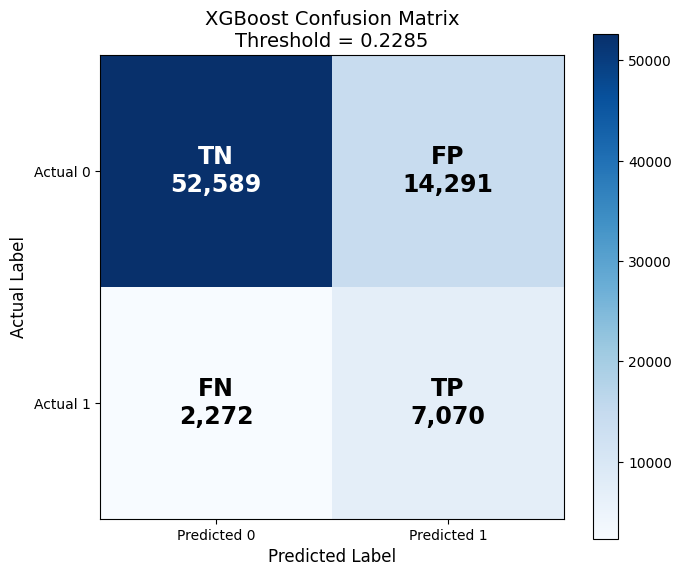

In [102]:
# ============================================================
# 최종 XGBoost - Confusion Matrix 전체 코드
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    roc_auc_score,
    average_precision_score
)


# ------------------------------------------------------------
# 1. 최종 모델 / 최적 Threshold 지정
# ------------------------------------------------------------

final_model = xgboost_search.best_estimator_

final_threshold = best_thresholds["XGBoost"]


# ------------------------------------------------------------
# 2. Validation 예측
# ------------------------------------------------------------

# Response = 1일 확률
y_valid_prob = final_model.predict_proba(
    X_valid
)[:, 1]

# OOF에서 결정한 최적 threshold 적용
y_valid_pred = (
    y_valid_prob >= final_threshold
).astype(int)


# ------------------------------------------------------------
# 3. Confusion Matrix 계산
# ------------------------------------------------------------

cm = confusion_matrix(
    y_valid,
    y_valid_pred
)

# [[TN, FP],
#  [FN, TP]]

tn, fp, fn, tp = cm.ravel()


# ------------------------------------------------------------
# 4. 성능 출력
# ------------------------------------------------------------

print("=" * 50)
print("Final XGBoost Validation Result")
print("=" * 50)

print(f"Threshold : {final_threshold:.6f}")

print()

print("Confusion Matrix")
print(cm)

print()

print(f"TN : {tn:,}")
print(f"FP : {fp:,}")
print(f"FN : {fn:,}")
print(f"TP : {tp:,}")

print()

print(
    "Accuracy  :",
    accuracy_score(
        y_valid,
        y_valid_pred
    )
)

print(
    "Precision :",
    precision_score(
        y_valid,
        y_valid_pred,
        zero_division=0
    )
)

print(
    "Recall    :",
    recall_score(
        y_valid,
        y_valid_pred,
        zero_division=0
    )
)

print(
    "F1 Score  :",
    f1_score(
        y_valid,
        y_valid_pred
    )
)

print(
    "ROC-AUC   :",
    roc_auc_score(
        y_valid,
        y_valid_prob
    )
)

print(
    "AP        :",
    average_precision_score(
        y_valid,
        y_valid_prob
    )
)


# ------------------------------------------------------------
# 5. Confusion Matrix 시각화
#    TN / FP / FN / TP + 실제 숫자 표시
# ------------------------------------------------------------

labels = np.array([
    ["TN", "FP"],
    ["FN", "TP"]
])

fig, ax = plt.subplots(
    figsize=(7, 6)
)

# 혼동행렬 이미지
im = ax.imshow(
    cm,
    cmap="Blues"
)

# 오른쪽 Colorbar
plt.colorbar(
    im,
    ax=ax
)

# 색상 기준
color_threshold = cm.max() / 2


# 각 칸에 TN / FP / FN / TP + 숫자 표시
for i in range(2):

    for j in range(2):

        text_color = (
            "white"
            if cm[i, j] > color_threshold
            else "black"
        )

        ax.text(
            j,
            i,
            f"{labels[i, j]}\n{cm[i, j]:,}",
            ha="center",
            va="center",
            fontsize=17,
            fontweight="bold",
            color=text_color
        )


# ------------------------------------------------------------
# 6. 축 설정
# ------------------------------------------------------------

ax.set_xticks(
    [0, 1]
)

ax.set_yticks(
    [0, 1]
)

ax.set_xticklabels([
    "Predicted 0",
    "Predicted 1"
])

ax.set_yticklabels([
    "Actual 0",
    "Actual 1"
])

ax.set_xlabel(
    "Predicted Label",
    fontsize=12
)

ax.set_ylabel(
    "Actual Label",
    fontsize=12
)

ax.set_title(
    f"XGBoost Confusion Matrix\n"
    f"Threshold = {final_threshold:.4f}",
    fontsize=14
)

plt.tight_layout()
plt.show()

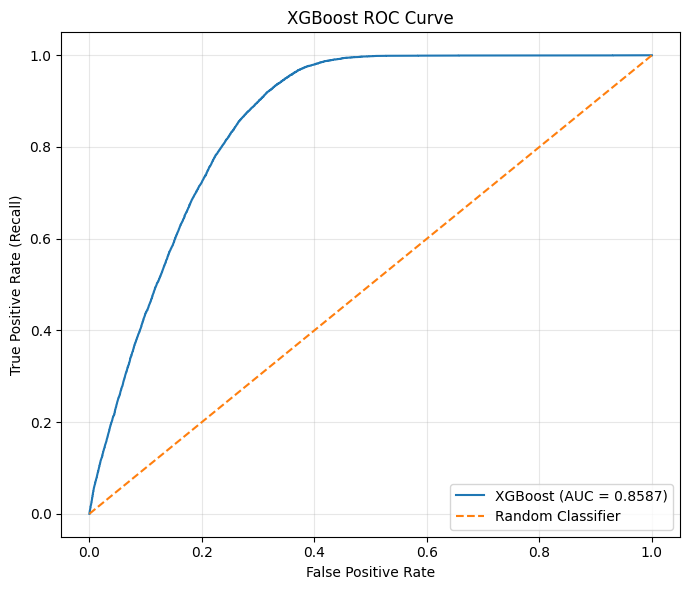

In [103]:
# ============================================================
# 2-1. ROC Curve
# ============================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

# ROC 계산
fpr, tpr, roc_thresholds = roc_curve(
    y_valid,
    y_valid_prob
)

roc_auc = roc_auc_score(
    y_valid,
    y_valid_prob
)

# 그래프
plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"XGBoost (AUC = {roc_auc:.4f})"
)

# Random classifier 기준선
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate (Recall)"
)

plt.title(
    "XGBoost ROC Curve"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()

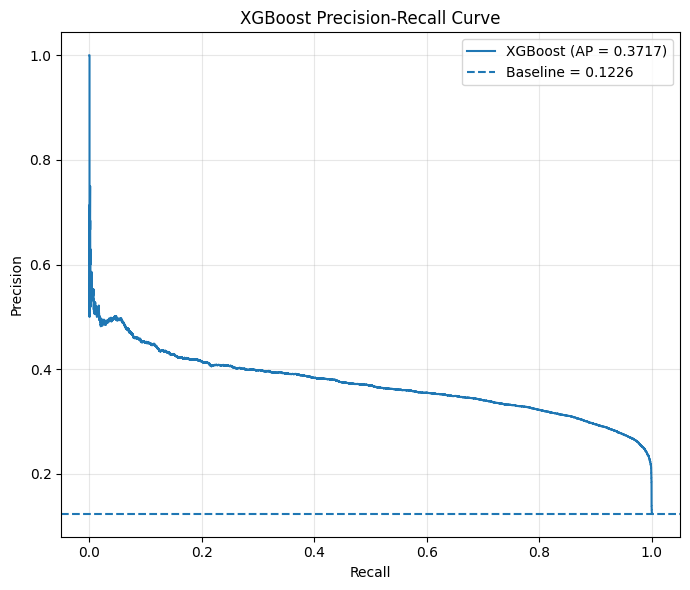

In [104]:
# ============================================================
# 2-2. Precision-Recall Curve
# ============================================================

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# PR Curve 계산
precision_curve, recall_curve, pr_thresholds = (
    precision_recall_curve(
        y_valid,
        y_valid_prob
    )
)

ap_score = average_precision_score(
    y_valid,
    y_valid_prob
)

# Positive 클래스 비율
positive_rate = y_valid.mean()

# 그래프
plt.figure(figsize=(7, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"XGBoost (AP = {ap_score:.4f})"
)

# Random classifier 기준선
plt.axhline(
    y=positive_rate,
    linestyle="--",
    label=f"Baseline = {positive_rate:.4f}"
)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "XGBoost Precision-Recall Curve"
)

plt.legend(
    loc="upper right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [105]:
# ============================================================
# 3-1. XGBoost Feature Importance
# One-Hot Encoding 이후 세부 변수 기준
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# 최종 Pipeline에서 전처리기와 XGBoost 모델 분리
final_preprocessor = final_model.named_steps["preprocessor"]
final_xgb = final_model.named_steps["model"]


# 전처리 이후 feature 이름
feature_names = (
    final_preprocessor
    .get_feature_names_out()
)


# XGBoost Booster
booster = final_xgb.get_booster()


# Gain 기준 중요도
gain_score = booster.get_score(
    importance_type="gain"
)


# f0, f1, f2 ... 와 실제 feature 이름 연결
gain_importances = np.array([
    gain_score.get(
        f"f{i}",
        0.0
    )
    for i in range(len(feature_names))
])


# 합이 1이 되도록 정규화
if gain_importances.sum() > 0:
    gain_importances = (
        gain_importances
        / gain_importances.sum()
    )


# DataFrame 생성
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": gain_importances
})


# 이름 보기 좋게 정리
feature_importance_df["Feature"] = (
    feature_importance_df["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("binary__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)


feature_importance_df = (
    feature_importance_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)


# 상위 20개 출력
feature_importance_df.head(20)

,Feature,Importance
0,Vehicle_Damage,0.393393
1,Previously_Insured,0.381704
2,Policy_Sales_Channel_152.0,0.021608
3,Policy_Sales_Channel_160.0,0.020372
4,Vehicle_Age_< 1 Year,0.013452
5,Age,0.011223
6,Policy_Sales_Channel_163.0,0.005440
7,Vehicle_Age_1-2 Year,0.005003
8,Policy_Sales_Channel_26.0,0.004902
9,Vehicle_Age_> 2 Years,0.004775


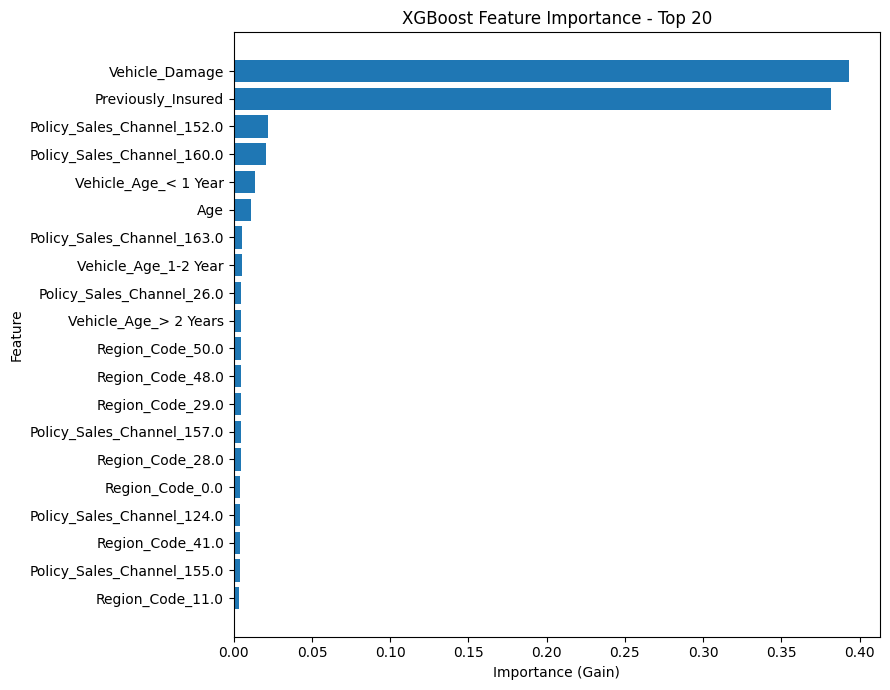

In [106]:
# ============================================================
# 세부 Feature Importance Top 20 시각화
# ============================================================

top20 = (
    feature_importance_df
    .head(20)
    .sort_values(
        "Importance",
        ascending=True
    )
)

plt.figure(
    figsize=(9, 7)
)

plt.barh(
    top20["Feature"],
    top20["Importance"]
)

plt.xlabel(
    "Importance (Gain)"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "XGBoost Feature Importance - Top 20"
)

plt.tight_layout()
plt.show()

In [107]:
# ============================================================
# 3-2. 원래 변수 기준 Feature Importance 통합
# ============================================================

original_importance = []


# 전처리 전 feature 이름 다시 가져오기
raw_feature_names = (
    final_preprocessor
    .get_feature_names_out()
)


for feature_name, importance in zip(
    raw_feature_names,
    gain_importances
):

    # ----------------------------------
    # Numeric
    # ----------------------------------
    if feature_name.startswith("num__"):

        original_feature = (
            feature_name
            .replace("num__", "")
        )

    # ----------------------------------
    # Binary
    # ----------------------------------
    elif feature_name.startswith(
        "binary__"
    ):

        original_feature = (
            feature_name
            .replace("binary__", "")
        )

    # ----------------------------------
    # Categorical / One-Hot
    # ----------------------------------
    elif feature_name.startswith(
        "cat__"
    ):

        clean_name = (
            feature_name
            .replace("cat__", "")
        )

        original_feature = None

        for col in categorical_cols:

            if clean_name.startswith(
                col + "_"
            ):

                original_feature = col
                break

        if original_feature is None:
            original_feature = clean_name

    else:
        original_feature = feature_name


    original_importance.append({
        "Feature": original_feature,
        "Importance": importance
    })


# DataFrame
original_importance_df = pd.DataFrame(
    original_importance
)


# 같은 원래 변수끼리 Importance 합산
original_importance_df = (
    original_importance_df
    .groupby(
        "Feature",
        as_index=False
    )["Importance"]
    .sum()
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)


original_importance_df

,Feature,Importance
0,Vehicle_Damage,0.393393
1,Previously_Insured,0.381704
2,Policy_Sales_Channel,0.098987
3,Region_Code,0.085469
4,Vehicle_Age,0.023230
5,Age,0.011223
6,Driving_License,0.002525
7,Gender,0.001368
8,Annual_Premium,0.001265
9,Vintage,0.000836


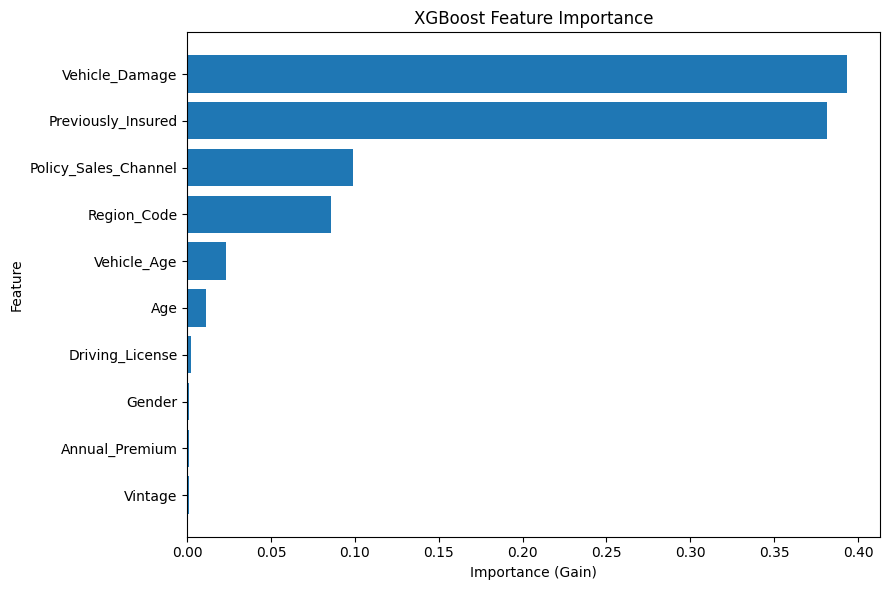

In [108]:
# ============================================================
# 원래 변수 기준 Feature Importance 시각화
# ============================================================

plot_importance = (
    original_importance_df
    .sort_values(
        "Importance",
        ascending=True
    )
)

plt.figure(
    figsize=(9, 6)
)

plt.barh(
    plot_importance["Feature"],
    plot_importance["Importance"]
)

plt.xlabel(
    "Importance (Gain)"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "XGBoost Feature Importance"
)

plt.tight_layout()
plt.show()

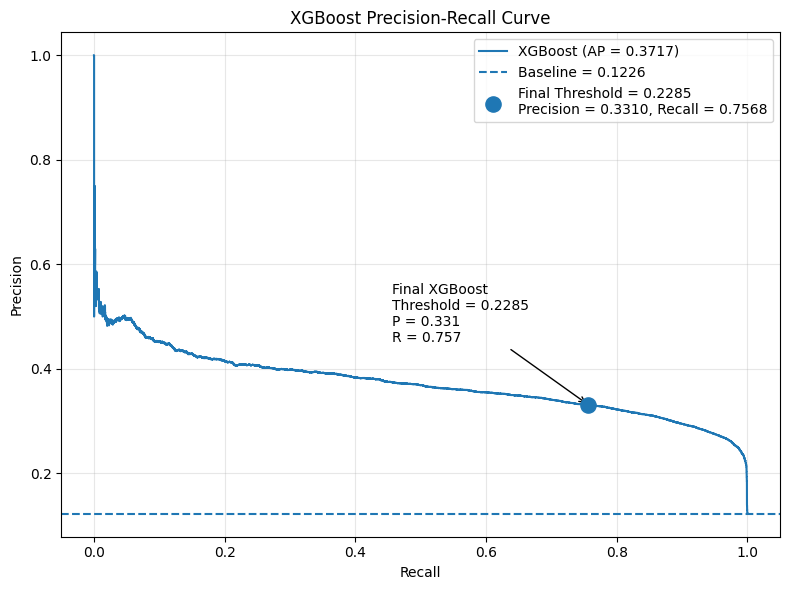

In [109]:
# ============================================================
# XGBoost Precision-Recall Curve
# + 최종 Threshold 위치 표시
# ============================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    precision_score,
    recall_score
)

# ------------------------------------------------------------
# 1. PR Curve 계산
# ------------------------------------------------------------

precision_curve, recall_curve, pr_thresholds = (
    precision_recall_curve(
        y_valid,
        y_valid_prob
    )
)

ap_score = average_precision_score(
    y_valid,
    y_valid_prob
)

# Positive 클래스 비율 = Random Baseline
positive_rate = y_valid.mean()


# ------------------------------------------------------------
# 2. 최종 XGBoost 지점 계산
# ------------------------------------------------------------

final_precision = precision_score(
    y_valid,
    y_valid_pred
)

final_recall = recall_score(
    y_valid,
    y_valid_pred
)


# ------------------------------------------------------------
# 3. PR Curve 시각화
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

# PR Curve
plt.plot(
    recall_curve,
    precision_curve,
    label=f"XGBoost (AP = {ap_score:.4f})"
)

# Random Baseline
plt.axhline(
    y=positive_rate,
    linestyle="--",
    label=f"Baseline = {positive_rate:.4f}"
)

# ------------------------------------------------------------
# 최종 Threshold 위치 표시
# ------------------------------------------------------------

plt.scatter(
    final_recall,
    final_precision,
    s=120,
    zorder=5,
    label=(
        f"Final Threshold = {final_threshold:.4f}\n"
        f"Precision = {final_precision:.4f}, "
        f"Recall = {final_recall:.4f}"
    )
)

# 점 옆에 설명 표시
plt.annotate(
    (
        f"Final XGBoost\n"
        f"Threshold = {final_threshold:.4f}\n"
        f"P = {final_precision:.3f}\n"
        f"R = {final_recall:.3f}"
    ),
    xy=(
        final_recall,
        final_precision
    ),
    xytext=(
        final_recall - 0.30,
        final_precision + 0.12
    ),
    arrowprops=dict(
        arrowstyle="->"
    ),
    fontsize=10
)


# ------------------------------------------------------------
# 4. 그래프 설정
# ------------------------------------------------------------

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "XGBoost Precision-Recall Curve"
)

plt.legend(
    loc="upper right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [111]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [112]:
# ============================================================
# 4-1. SHAP 분석 준비
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 최종 Pipeline에서 전처리기 / XGBoost 분리
final_preprocessor = final_model.named_steps["preprocessor"]
final_xgb = final_model.named_steps["model"]

# Validation 데이터 중 3,000개만 샘플링
X_shap = X_valid.sample(
    n=min(3000, len(X_valid)),
    random_state=42
)

# Pipeline의 전처리 적용
X_shap_transformed = final_preprocessor.transform(X_shap)

# SHAP 시각화를 위해 dense 형태로 변환
if hasattr(X_shap_transformed, "toarray"):
    X_shap_transformed = X_shap_transformed.toarray()

# 전처리 후 변수명
shap_feature_names = (
    final_preprocessor
    .get_feature_names_out()
)

# 이름 정리
shap_feature_names = [
    name
    .replace("num__", "")
    .replace("binary__", "")
    .replace("cat__", "")
    for name in shap_feature_names
]

# SHAP Explainer
explainer = shap.TreeExplainer(
    final_xgb
)

shap_values = explainer(
    X_shap_transformed
)

print("SHAP 데이터 크기 :", X_shap_transformed.shape)
print("SHAP 계산 완료")

SHAP 데이터 크기 : (3000, 217)
SHAP 계산 완료


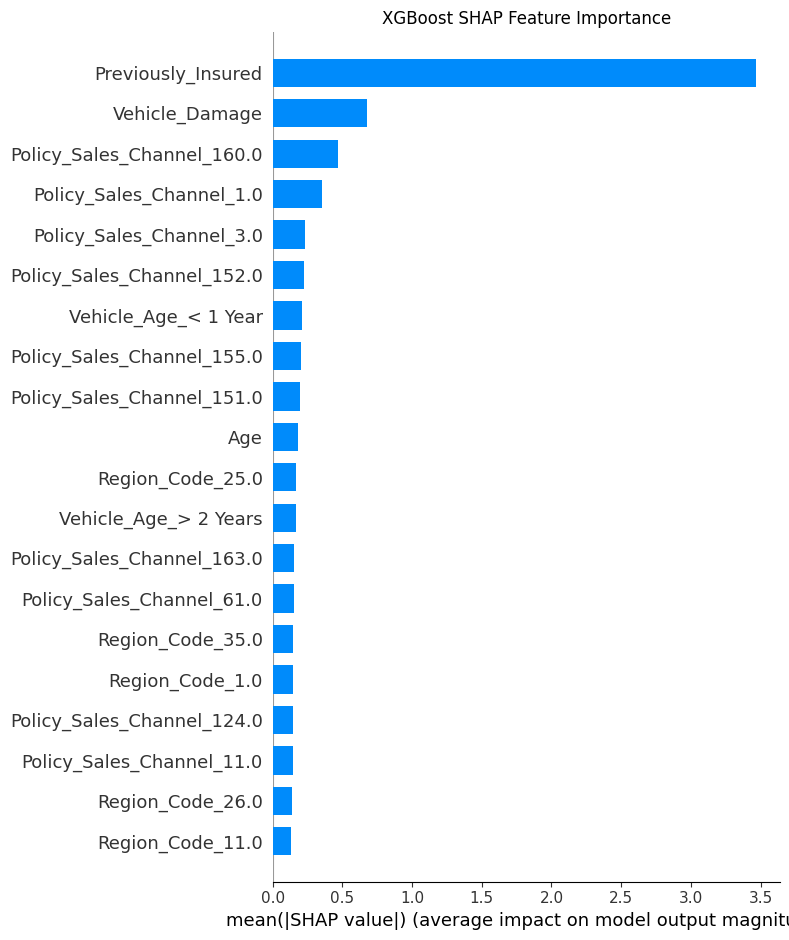

In [113]:
# ============================================================
# 4-2. SHAP Feature Importance
# ============================================================

shap.summary_plot(
    shap_values.values,
    X_shap_transformed,
    feature_names=shap_feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.title(
    "XGBoost SHAP Feature Importance"
)

plt.tight_layout()
plt.show()

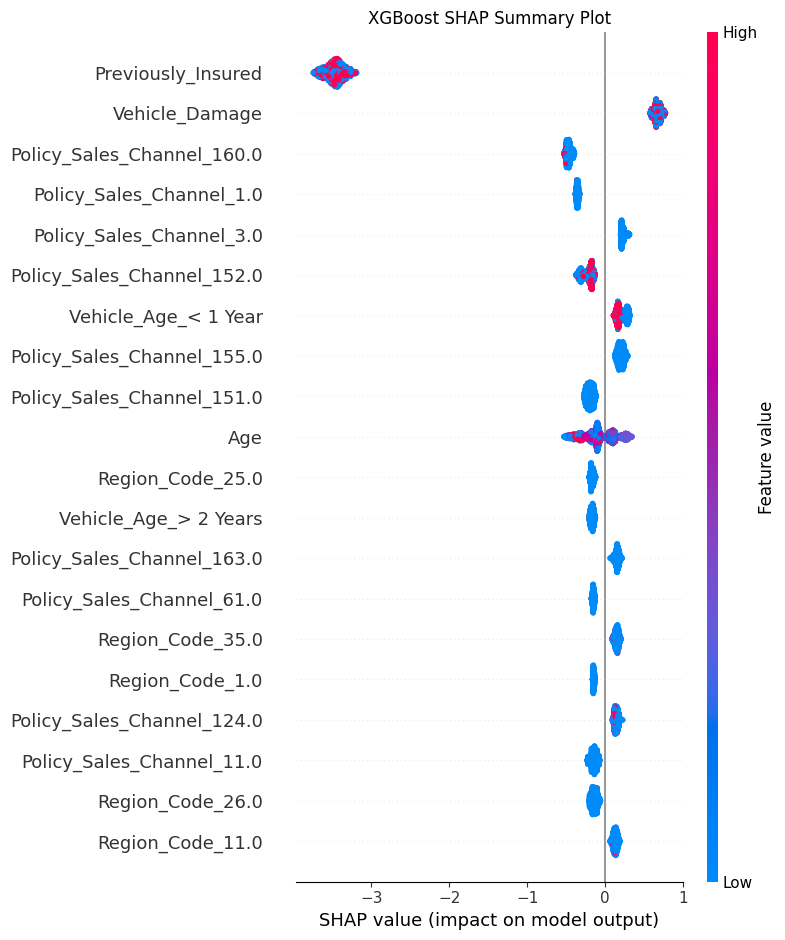

In [114]:
# ============================================================
# 4-3. SHAP Summary Plot
# ============================================================

shap.summary_plot(
    shap_values.values,
    X_shap_transformed,
    feature_names=shap_feature_names,
    max_display=20,
    show=False
)

plt.title(
    "XGBoost SHAP Summary Plot"
)

plt.tight_layout()
plt.show()

In [115]:
# ============================================================
# 5. 전체 Train 데이터로 최종 XGBoost 학습
# ============================================================

from sklearn.base import clone

# 기존에 확정한 XGBoost 복사
production_model = clone(
    xgboost_search.best_estimator_
)

# 전체 train 데이터 사용
production_model.fit(
    X,
    y
)

# Threshold도 기존 OOF 결과 그대로 사용
production_threshold = best_thresholds[
    "XGBoost"
]

print("전체 Train 학습 완료")
print("Train Shape :", X.shape)
print(
    "Final Threshold :",
    production_threshold
)

전체 Train 학습 완료
Train Shape : (381109, 10)
Final Threshold : 0.22849713265895844


In [116]:
# ============================================================
# 6. Test 데이터 예측
# ============================================================

# Response=1 예측 확률
test_prob = production_model.predict_proba(
    X_test
)[:, 1]

# 우리가 확정한 threshold 적용
test_pred = (
    test_prob >= production_threshold
).astype(int)

print("Test 데이터 수 :", len(test_pred))

print()
print("예측 클래스 분포")

print(
    pd.Series(test_pred)
    .value_counts()
    .sort_index()
)

print()
print("Response=1 예측 비율 :")
print(test_pred.mean())

Test 데이터 수 : 127037

예측 클래스 분포
0    91360
1    35677
dtype: int64

Response=1 예측 비율 :
0.280839440477971


In [117]:
# ============================================================
# 7-1. 최종 Submission - Class Prediction
# ============================================================

submission = pd.DataFrame({
    "id": test["id"],
    "Response": test_pred
})

submission.head()

,id,Response
0,381110,0
1,381111,1
2,381112,1
3,381113,0
4,381114,0


In [118]:
print(submission.shape)

print()

print(
    submission["Response"]
    .value_counts()
)

submission.head(10)

(127037, 2)

0    91360
1    35677
Name: Response, dtype: int64


,id,Response
0,381110,0
1,381111,1
2,381112,1
3,381113,0
4,381114,0
5,381115,0
6,381116,0
7,381117,0
8,381118,1
9,381119,0


In [119]:
submission.to_csv(
    "submission.csv",
    index=False
)

print(
    "submission.csv 저장 완료"
)

submission.csv 저장 완료


In [120]:
# ============================================================
# 7-2. Probability Prediction 저장
# ============================================================

submission_probability = pd.DataFrame({
    "id": test["id"],
    "Response": test_prob
})

submission_probability.to_csv(
    "submission_probability.csv",
    index=False
)

submission_probability.head()

,id,Response
0,381110,0.000692
1,381111,0.319665
2,381112,0.307560
3,381113,0.004864
4,381114,0.000441


In [121]:
# ============================================================
# 8. 최종 모델 저장
# ============================================================

import joblib

joblib.dump(
    production_model,
    "final_xgboost_model.pkl"
)

joblib.dump(
    {
        "threshold": production_threshold
    },
    "final_xgboost_threshold.pkl"
)

print(
    "최종 모델 저장 완료"
)

최종 모델 저장 완료


In [ ]:
##### 아래는 PPT 제작하면서 필요한 데이터 추가로 출력한 코드

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


results = pd.DataFrame({
    'Model': ['XGBoost', 'Gradient Boosting', 'LightGBM'],
    'ROC-AUC': [0.858674, 0.8583, 0.8584],
    'F1-score': [0.460541, 0.4604, 0.4583],
    'AP': [0.371691, 0.3712, 0.3710]
})


display(results.round(4))

,Model,ROC-AUC,F1-score,AP
0,XGBoost,0.8587,0.4605,0.3717
1,Gradient Boosting,0.8583,0.4604,0.3712
2,LightGBM,0.8584,0.4583,0.3710


In [4]:
import os
import joblib

model_for_importance = joblib.load("final_xgboost_model.pkl")

print(type(model_for_importance))

<class 'sklearn.pipeline.Pipeline'>


In [5]:
preprocessor = model_for_importance.named_steps["preprocessor"]
xgb_model = model_for_importance.named_steps["model"]

print(type(preprocessor))
print(type(xgb_model))

<class 'sklearn.compose._column_transformer.ColumnTransformer'>
<class 'xgboost.sklearn.XGBClassifier'>


In [6]:
feature_names = preprocessor.get_feature_names_out()

print("전처리 후 피처 개수:", len(feature_names))
print(feature_names[:30])

전처리 후 피처 개수: 218
['num__Age' 'num__Annual_Premium' 'num__Vintage' 'binary__Gender'
 'binary__Driving_License' 'binary__Previously_Insured'
 'binary__Vehicle_Damage' 'cat__Region_Code_0.0' 'cat__Region_Code_1.0'
 'cat__Region_Code_2.0' 'cat__Region_Code_3.0' 'cat__Region_Code_4.0'
 'cat__Region_Code_5.0' 'cat__Region_Code_6.0' 'cat__Region_Code_7.0'
 'cat__Region_Code_8.0' 'cat__Region_Code_9.0' 'cat__Region_Code_10.0'
 'cat__Region_Code_11.0' 'cat__Region_Code_12.0' 'cat__Region_Code_13.0'
 'cat__Region_Code_14.0' 'cat__Region_Code_15.0' 'cat__Region_Code_16.0'
 'cat__Region_Code_17.0' 'cat__Region_Code_18.0' 'cat__Region_Code_19.0'
 'cat__Region_Code_20.0' 'cat__Region_Code_21.0' 'cat__Region_Code_22.0']


In [7]:
import pandas as pd
import numpy as np

booster = xgb_model.get_booster()

gain_scores = booster.get_score(
    importance_type="gain"
)

print("Gain 값이 있는 피처 수:", len(gain_scores))
list(gain_scores.items())[:10]

Gain 값이 있는 피처 수: 99


[('f0', 34.70537567138672),
 ('f1', 4.369198322296143),
 ('f2', 2.610090970993042),
 ('f3', 4.641139030456543),
 ('f4', 8.988837242126465),
 ('f5', 1465.783203125),
 ('f6', 1416.181396484375),
 ('f7', 16.97946548461914),
 ('f8', 5.581749439239502),
 ('f9', 4.386207103729248)]

In [8]:
importance_values = np.zeros(len(feature_names))

for key, value in gain_scores.items():
    idx = int(key.replace("f", ""))
    importance_values[idx] = value

importance_df = pd.DataFrame({
    "transformed_feature": feature_names,
    "importance": importance_values
})

importance_df = (
    importance_df
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

importance_df.head(20)

,transformed_feature,importance
0,binary__Previously_Insured,1465.783203
1,binary__Vehicle_Damage,1416.181396
2,cat__Policy_Sales_Channel_152.0,171.103195
3,cat__Policy_Sales_Channel_160.0,109.570023
4,num__Age,34.705376
5,cat__Vehicle_Age_< 1 Year,32.972607
6,cat__Policy_Sales_Channel_26.0,26.647421
7,cat__Vehicle_Age_> 2 Years,22.592060
8,cat__Policy_Sales_Channel_124.0,20.799427
9,cat__Vehicle_Age_1-2 Year,18.432362


In [9]:
# 원래 변수 그룹 정의
numeric_cols = [
    "Age",
    "Annual_Premium",
    "Vintage"
]

binary_cols = [
    "Gender",
    "Driving_License",
    "Previously_Insured",
    "Vehicle_Damage"
]

categorical_cols = [
    "Region_Code",
    "Vehicle_Age",
    "Policy_Sales_Channel"
]

In [10]:
# XGBoost Total Gain Importance
total_gain_scores = booster.get_score(
    importance_type="total_gain"
)

total_gain_values = np.zeros(len(feature_names))

for key, value in total_gain_scores.items():
    idx = int(key.replace("f", ""))
    total_gain_values[idx] = value

total_gain_df = pd.DataFrame({
    "transformed_feature": feature_names,
    "importance": total_gain_values
})

total_gain_df.head()

,transformed_feature,importance
0,num__Age,73505.984375
1,num__Annual_Premium,8432.552734
2,num__Vintage,5395.058105
3,binary__Gender,1772.915039
4,binary__Driving_License,557.307922


In [11]:
def get_original_feature_name(feature_name):

    # num__Age -> Age
    # binary__Gender -> Gender
    # cat__Region_Code_28.0 -> Region_Code

    if "__" in feature_name:
        feature_name = feature_name.split("__", 1)[1]

    # 수치형
    for col in numeric_cols:
        if feature_name == col:
            return col

    # 이진형
    for col in binary_cols:
        if feature_name == col:
            return col

    # One-Hot Encoding된 범주형
    for col in categorical_cols:
        if feature_name == col or feature_name.startswith(col + "_"):
            return col

    return feature_name

In [12]:
total_gain_df["feature"] = (
    total_gain_df["transformed_feature"]
    .apply(get_original_feature_name)
)

original_importance_df = (
    total_gain_df
    .groupby("feature", as_index=False)["importance"]
    .sum()
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

original_importance_df

,feature,importance
0,Vehicle_Damage,283236.281250
1,Previously_Insured,263840.968750
2,Age,73505.984375
3,Policy_Sales_Channel,66803.528947
4,Region_Code,16581.818960
5,Vehicle_Age,13546.560791
6,Annual_Premium,8432.552734
7,Vintage,5395.058105
8,Gender,1772.915039
9,Driving_License,557.307922


In [13]:
original_importance_df["importance_ratio"] = (
    original_importance_df["importance"]
    / original_importance_df["importance"].sum()
)

original_importance_df["importance_pct"] = (
    original_importance_df["importance_ratio"] * 100
)

original_importance_df

,feature,importance,importance_ratio,importance_pct
0,Vehicle_Damage,283236.281250,0.386052,38.605249
1,Previously_Insured,263840.968750,0.359617,35.961658
2,Age,73505.984375,0.100189,10.018903
3,Policy_Sales_Channel,66803.528947,0.091054,9.105355
4,Region_Code,16581.818960,0.022601,2.260110
5,Vehicle_Age,13546.560791,0.018464,1.846403
6,Annual_Premium,8432.552734,0.011494,1.149361
7,Vintage,5395.058105,0.007353,0.735349
8,Gender,1772.915039,0.002416,0.241649
9,Driving_License,557.307922,0.000760,0.075961


In [14]:
for _, row in original_importance_df.iterrows():
    print(
        f'  {{ feature: "{row["feature"]}", '
        f'value: {row["importance_ratio"]:.6f} }},'
    )

  { feature: "Vehicle_Damage", value: 0.386052 },
  { feature: "Previously_Insured", value: 0.359617 },
  { feature: "Age", value: 0.100189 },
  { feature: "Policy_Sales_Channel", value: 0.091054 },
  { feature: "Region_Code", value: 0.022601 },
  { feature: "Vehicle_Age", value: 0.018464 },
  { feature: "Annual_Premium", value: 0.011494 },
  { feature: "Vintage", value: 0.007353 },
  { feature: "Gender", value: 0.002416 },
  { feature: "Driving_License", value: 0.000760 },


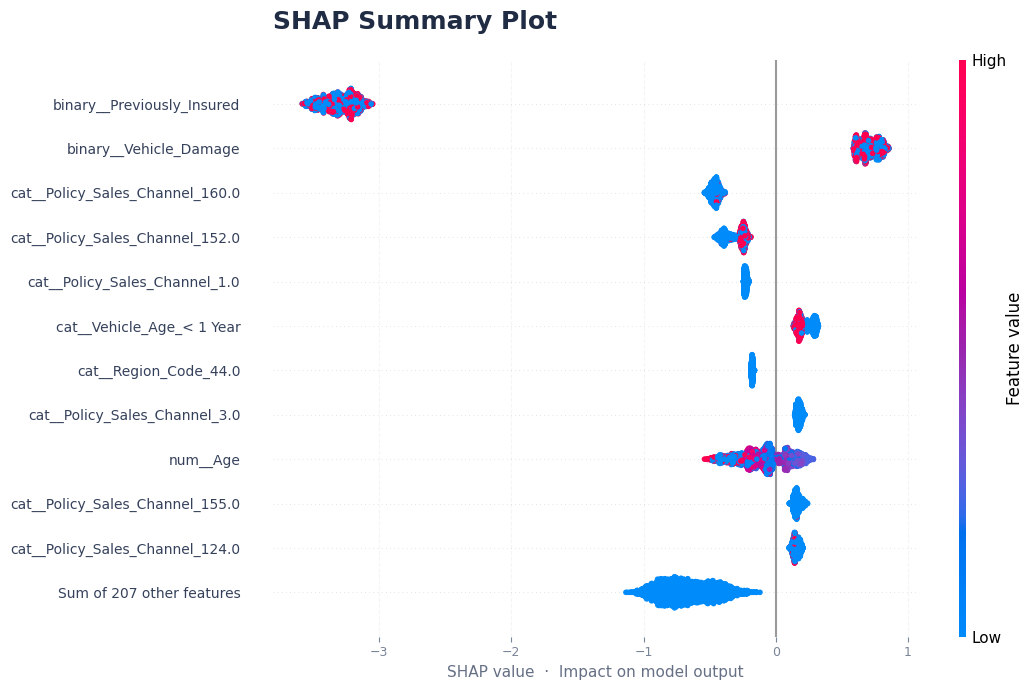

In [15]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt

# ============================================
# 1. 원본 데이터 다시 불러오기
# ============================================

train = pd.read_csv("train.csv")

X_shap = train.drop(
    columns=["id", "Response"]
).copy()


# ============================================
# 2. 학습 당시와 동일하게 이진 변수 변환
# ============================================

X_shap["Gender"] = (
    X_shap["Gender"]
    .map({
        "Female": 0,
        "Male": 1
    })
)

X_shap["Vehicle_Damage"] = (
    X_shap["Vehicle_Damage"]
    .map({
        "No": 0,
        "Yes": 1
    })
)


# ============================================
# 3. 너무 많은 데이터를 그리면 복잡하므로
#    3,000개만 랜덤 샘플링
# ============================================

X_shap_sample = X_shap.sample(
    n=3000,
    random_state=42
)


# ============================================
# 4. 최종 Pipeline의 전처리 적용
# ============================================

preprocessor = model_for_importance.named_steps["preprocessor"]
xgb_model = model_for_importance.named_steps["model"]

X_shap_transformed = preprocessor.transform(
    X_shap_sample
)

feature_names = preprocessor.get_feature_names_out()


# sparse matrix라면 dense 변환
if hasattr(X_shap_transformed, "toarray"):
    X_shap_transformed = X_shap_transformed.toarray()


# ============================================
# 5. SHAP 계산
# ============================================

explainer = shap.TreeExplainer(
    xgb_model
)

shap_values = explainer(
    X_shap_transformed
)


# feature 이름 적용
shap_values.feature_names = list(
    feature_names
)


# ============================================
# 6. SHAP Summary Beeswarm
# ============================================

plt.figure(figsize=(11, 7))

shap.plots.beeswarm(
    shap_values,
    max_display=12,
    show=False,
    plot_size=None
)

fig = plt.gcf()
ax = plt.gca()


# ============================================
# 7. 밝은 Dashboard 테마에 맞게 디자인
# ============================================

fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

ax.set_title(
    "SHAP Summary Plot",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=22,
    color="#202B44"
)

ax.set_xlabel(
    "SHAP value  ·  Impact on model output",
    fontsize=11,
    color="#667085"
)

ax.tick_params(
    axis="x",
    colors="#7A8498",
    labelsize=9
)

ax.tick_params(
    axis="y",
    colors="#35415B",
    labelsize=10
)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.12
)

plt.tight_layout()


# ============================================
# 8. 고해상도 이미지 저장
# ============================================

plt.savefig(
    "shap_summary.png",
    dpi=220,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

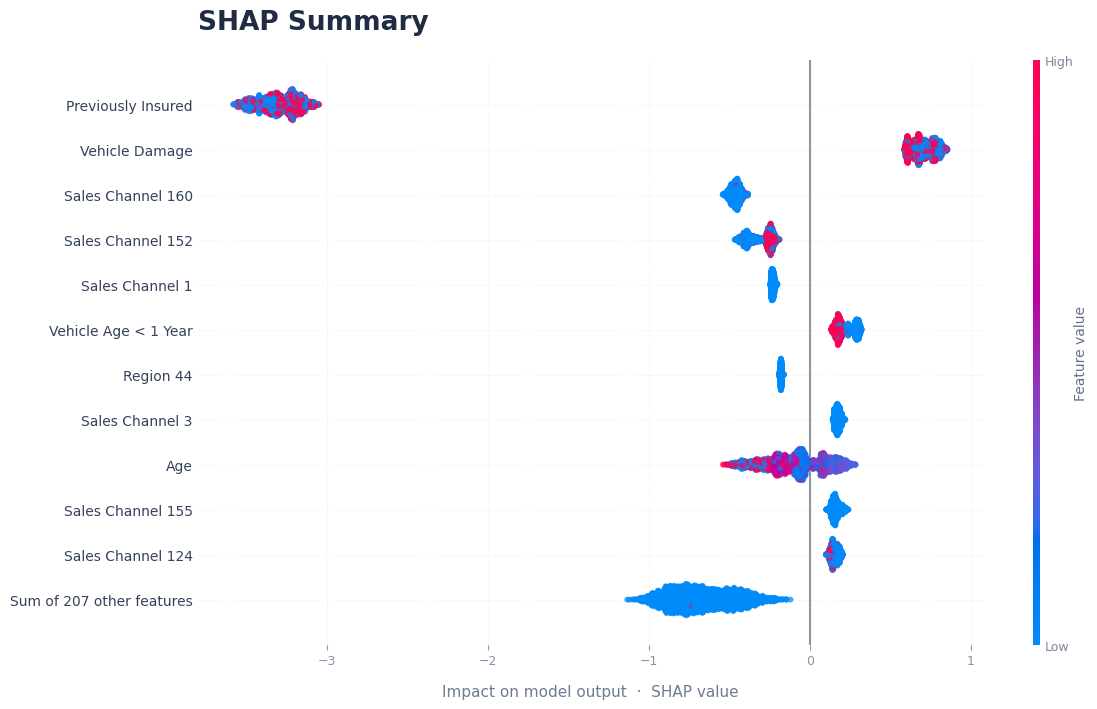

In [16]:
import copy
import matplotlib.pyplot as plt
import shap


# ============================================
# 1. SHAP 객체 복사
# ============================================

shap_dashboard = copy.deepcopy(shap_values)


# ============================================
# 2. 변수명 예쁘게 정리
# ============================================

def clean_feature_name(name):
    # Pipeline prefix 제거
    name = (
        name
        .replace("binary__", "")
        .replace("num__", "")
        .replace("cat__", "")
    )

    # 주요 변수명 정리
    if name == "Previously_Insured":
        return "Previously Insured"

    if name == "Vehicle_Damage":
        return "Vehicle Damage"

    if name == "Annual_Premium":
        return "Annual Premium"

    if name == "Driving_License":
        return "Driving License"

    if name.startswith("Policy_Sales_Channel_"):
        value = name.replace("Policy_Sales_Channel_", "")
        value = value.replace(".0", "")
        return f"Sales Channel {value}"

    if name.startswith("Region_Code_"):
        value = name.replace("Region_Code_", "")
        value = value.replace(".0", "")
        return f"Region {value}"

    if name.startswith("Vehicle_Age_"):
        value = name.replace("Vehicle_Age_", "")
        return f"Vehicle Age {value}"

    return name.replace("_", " ")


shap_dashboard.feature_names = [
    clean_feature_name(name)
    for name in shap_dashboard.feature_names
]


# ============================================
# 3. Dashboard용 SHAP Beeswarm
# ============================================

fig, ax = plt.subplots(
    figsize=(12, 7.2)
)

fig.patch.set_alpha(0)
ax.set_facecolor("none")


shap.plots.beeswarm(
    shap_dashboard,
    max_display=12,
    show=False,
    plot_size=None,
    alpha=0.72,
    s=18,
    color_bar=True,
    color_bar_label="Feature value",
    group_remaining_features=True
)


ax = plt.gca()


# ============================================
# 4. 제목
# ============================================

ax.set_title(
    "SHAP Summary",
    loc="left",
    fontsize=19,
    fontweight=700,
    color="#202B44",
    pad=22
)


# ============================================
# 5. X축
# ============================================

ax.set_xlabel(
    "Impact on model output  ·  SHAP value",
    fontsize=11,
    color="#6F7B91",
    labelpad=12
)


# ============================================
# 6. 축 / 글자 스타일
# ============================================

ax.tick_params(
    axis="x",
    colors="#8993A7",
    labelsize=9
)

ax.tick_params(
    axis="y",
    colors="#35415B",
    labelsize=10,
    length=0
)


# ============================================
# 7. 기준선 및 Grid
# ============================================

ax.axvline(
    0,
    color="#8390A8",
    linewidth=1.2,
    alpha=0.55,
    zorder=0
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.7,
    alpha=0.10
)


# ============================================
# 8. 불필요한 테두리 제거
# ============================================

for spine in ax.spines.values():
    spine.set_visible(False)


# ============================================
# 9. Colorbar 스타일
# ============================================

fig = plt.gcf()

# SHAP colorbar가 두 번째 axes로 생성됨
if len(fig.axes) > 1:
    cbar_ax = fig.axes[-1]

    cbar_ax.tick_params(
        labelsize=9,
        colors="#7D8799",
        length=0
    )

    cbar_ax.yaxis.label.set_color(
        "#667085"
    )

    cbar_ax.yaxis.label.set_fontsize(
        10
    )


# ============================================
# 10. 여백
# ============================================

plt.tight_layout()


# ============================================
# 11. 웹용 저장
# ============================================

plt.savefig(
    "shap_summary_dashboard.png",
    dpi=240,
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    "shap_summary_dashboard.svg",
    bbox_inches="tight",
    transparent=True
)

plt.show()

In [17]:
import json
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


# ============================================
# 1. 데이터 불러오기
# ============================================

train = pd.read_csv("train.csv")


# ============================================
# 2. 학습 때와 동일한 이진 변수 변환
# ============================================

train["Gender"] = train["Gender"].map({
    "Female": 0,
    "Male": 1
})

train["Vehicle_Damage"] = train["Vehicle_Damage"].map({
    "No": 0,
    "Yes": 1
})


# ============================================
# 3. X / y
# ============================================

X = train.drop(
    columns=["id", "Response"]
).copy()

y = train["Response"].copy()


# ============================================
# 4. 기존 프로젝트와 동일한 Hold-out Split
# ============================================

X_train_curve, X_valid_curve, y_train_curve, y_valid_curve = (
    train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )
)


print("Train:", X_train_curve.shape)
print("Valid:", X_valid_curve.shape)


# ============================================
# 5. 저장된 최종 XGBoost Pipeline 복제
#
# production_model은 전체 데이터로 학습됐기 때문에
# 직접 평가에 사용하지 않고 구조/파라미터만 복제
# ============================================

curve_model = clone(model_for_importance)

curve_model.fit(
    X_train_curve,
    y_train_curve
)


# ============================================
# 6. Validation 확률 예측
# ============================================

valid_prob = curve_model.predict_proba(
    X_valid_curve
)[:, 1]


# ============================================
# 7. ROC Curve
# ============================================

fpr, tpr, roc_thresholds = roc_curve(
    y_valid_curve,
    valid_prob
)

roc_auc = roc_auc_score(
    y_valid_curve,
    valid_prob
)


# ============================================
# 8. Precision-Recall Curve
# ============================================

precision, recall, pr_thresholds = (
    precision_recall_curve(
        y_valid_curve,
        valid_prob
    )
)

ap_score = average_precision_score(
    y_valid_curve,
    valid_prob
)

baseline = y_valid_curve.mean()


# ============================================
# 9. 최종 Threshold 지점
# ============================================

final_threshold = 0.2285

valid_pred = (
    valid_prob >= final_threshold
).astype(int)

final_precision = precision_score(
    y_valid_curve,
    valid_pred
)

final_recall = recall_score(
    y_valid_curve,
    valid_pred
)

final_f1 = f1_score(
    y_valid_curve,
    valid_pred
)


tn, fp, fn, tp = confusion_matrix(
    y_valid_curve,
    valid_pred
).ravel()

final_fpr = fp / (fp + tn)
final_tpr = tp / (tp + fn)


print()
print("ROC-AUC :", roc_auc)
print("AP      :", ap_score)
print("Baseline:", baseline)
print()
print("Threshold :", final_threshold)
print("Precision :", final_precision)
print("Recall    :", final_recall)
print("F1        :", final_f1)
print("FPR       :", final_fpr)
print("TPR       :", final_tpr)

Train: (304887, 10)
Valid: (76222, 10)

ROC-AUC : 0.8586737717083113
AP      : 0.3716908143849149
Baseline: 0.12256303954238934

Threshold : 0.2285
Precision : 0.3309770141847292
Recall    : 0.756797259687433
F1        : 0.46054131518092695
FPR       : 0.2136812200956938
TPR       : 0.756797259687433


In [18]:
# ============================================
# Curve Downsampling
# ============================================

def downsample_curve(x, y, max_points=250):

    if len(x) <= max_points:
        return [
            {
                "x": float(a),
                "y": float(b)
            }
            for a, b in zip(x, y)
        ]

    idx = np.linspace(
        0,
        len(x) - 1,
        max_points
    ).astype(int)

    return [
        {
            "x": float(x[i]),
            "y": float(y[i])
        }
        for i in idx
    ]


roc_points = downsample_curve(
    fpr,
    tpr
)


# precision_recall_curve는 recall이
# 1 → 0 방향이므로 웹 그래프용으로 뒤집기
pr_points = downsample_curve(
    recall[::-1],
    precision[::-1]
)


curve_data = {

    "summary": {
        "rocAuc": float(roc_auc),
        "ap": float(ap_score),
        "baseline": float(baseline),
        "threshold": float(final_threshold),
        "precision": float(final_precision),
        "recall": float(final_recall),
        "f1": float(final_f1),
        "fpr": float(final_fpr),
        "tpr": float(final_tpr)
    },

    "roc": roc_points,

    "pr": pr_points
}


# ============================================
# React public 폴더에 바로 저장
# ============================================

output_path = (
    "/Users/yoon/Documents/"
    "Machine_Learning/"
    "insurance-dashboard/"
    "public/model_curves.json"
)


with open(
    output_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        curve_data,
        f,
        ensure_ascii=False,
        indent=2
    )


print("저장 완료:")
print(output_path)

저장 완료:
/Users/yoon/Documents/Machine_Learning/insurance-dashboard/public/model_curves.json


In [19]:
import json
import numpy as np


# ============================================
# 1. 곡선 데이터 축소 함수
# ============================================

def downsample_curve(x, y, max_points=250):

    if len(x) <= max_points:
        return [
            {
                "x": float(a),
                "y": float(b)
            }
            for a, b in zip(x, y)
        ]

    idx = np.linspace(
        0,
        len(x) - 1,
        max_points
    ).astype(int)

    return [
        {
            "x": float(x[i]),
            "y": float(y[i])
        }
        for i in idx
    ]


# ============================================
# 2. ROC Curve
# ============================================

roc_points = downsample_curve(
    fpr,
    tpr
)


# ============================================
# 3. Precision-Recall Curve
#
# sklearn PR Curve는 recall이
# 1 → 0 방향이라 웹 그래프용으로 뒤집음
# ============================================

pr_points = downsample_curve(
    recall[::-1],
    precision[::-1]
)


# ============================================
# 4. JSON 데이터 구성
# ============================================

curve_data = {

    "summary": {

        "rocAuc": float(roc_auc),

        "ap": float(ap_score),

        "baseline": float(baseline),

        "threshold": float(final_threshold),

        "precision": float(final_precision),

        "recall": float(final_recall),

        "f1": float(final_f1),

        "fpr": float(final_fpr),

        "tpr": float(final_tpr)

    },

    "roc": roc_points,

    "pr": pr_points
}


# ============================================
# 5. React 프로젝트 public 폴더에 저장
# ============================================

output_path = (
    "/Users/yoon/Documents/"
    "Machine_Learning/"
    "insurance-dashboard/"
    "public/model_curves.json"
)


with open(
    output_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        curve_data,
        f,
        ensure_ascii=False,
        indent=2
    )


print("저장 완료:")
print(output_path)

print()
print("ROC points:", len(roc_points))
print("PR points :", len(pr_points))

저장 완료:
/Users/yoon/Documents/Machine_Learning/insurance-dashboard/public/model_curves.json

ROC points: 250
PR points : 250


In [20]:
%pip install phik

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.3/664.3 kB 20.4 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [21]:
import json
import pandas as pd
import numpy as np
import phik


# ============================================
# 1. 원본 Train 데이터
# ============================================

train_raw = pd.read_csv("train.csv")


print("Train shape:", train_raw.shape)
print("Response rate:", train_raw["Response"].mean())


# ============================================
# 2. 전체 관심 고객 비율
# ============================================

baseline = float(
    train_raw["Response"].mean()
)


# ============================================
# 3. Vehicle_Damage vs Response
# ============================================

vehicle_damage_df = (
    train_raw
    .groupby("Vehicle_Damage")["Response"]
    .agg(
        responseRate="mean",
        count="size"
    )
    .reset_index()
)


vehicle_damage_data = []

for _, row in vehicle_damage_df.iterrows():

    vehicle_damage_data.append({
        "label": str(row["Vehicle_Damage"]),
        "responseRate": float(row["responseRate"]),
        "count": int(row["count"])
    })


# ============================================
# 4. Previously_Insured vs Response
# ============================================

previous_df = (
    train_raw
    .groupby("Previously_Insured")["Response"]
    .agg(
        responseRate="mean",
        count="size"
    )
    .reset_index()
)


previous_data = []

for _, row in previous_df.iterrows():

    label = (
        "기존 보험 없음"
        if row["Previously_Insured"] == 0
        else "기존 보험 있음"
    )

    previous_data.append({
        "label": label,
        "value": int(row["Previously_Insured"]),
        "responseRate": float(row["responseRate"]),
        "count": int(row["count"])
    })


# ============================================
# 5. Age vs Response
#
# 임의 구간을 만들지 않고
# 실제 나이별 Response 비율 사용
# ============================================

age_df = (
    train_raw
    .groupby("Age")["Response"]
    .agg(
        responseRate="mean",
        count="size"
    )
    .reset_index()
    .sort_values("Age")
)


age_data = []

for _, row in age_df.iterrows():

    age_data.append({
        "age": int(row["Age"]),
        "responseRate": float(row["responseRate"]),
        "count": int(row["count"])
    })


# ============================================
# 6. Vehicle_Age vs Response
# ============================================

vehicle_age_df = (
    train_raw
    .groupby("Vehicle_Age")["Response"]
    .agg(
        responseRate="mean",
        count="size"
    )
    .reset_index()
)


# 보기 좋은 순서
vehicle_age_order = [
    "< 1 Year",
    "1-2 Year",
    "> 2 Years"
]


vehicle_age_df["sort"] = (
    vehicle_age_df["Vehicle_Age"]
    .map({
        value: index
        for index, value
        in enumerate(vehicle_age_order)
    })
)


vehicle_age_df = (
    vehicle_age_df
    .sort_values("sort")
)


vehicle_age_data = []

for _, row in vehicle_age_df.iterrows():

    vehicle_age_data.append({
        "label": str(row["Vehicle_Age"]),
        "responseRate": float(row["responseRate"]),
        "count": int(row["count"])
    })


# ============================================
# 7. 전체 Feature Association Heatmap
#
# id 제외
#
# Numeric:
# Age
# Annual_Premium
# Vintage
#
# 나머지는 범주형으로 처리
# ============================================

heatmap_df = (
    train_raw
    .drop(columns=["id"])
    .copy()
)


categorical_for_phik = [
    "Gender",
    "Driving_License",
    "Region_Code",
    "Previously_Insured",
    "Vehicle_Age",
    "Vehicle_Damage",
    "Policy_Sales_Channel",
    "Response"
]


for col in categorical_for_phik:

    heatmap_df[col] = (
        heatmap_df[col]
        .astype(str)
    )


interval_cols = [
    "Age",
    "Annual_Premium",
    "Vintage"
]


phik_matrix = (
    heatmap_df
    .phik_matrix(
        interval_cols=interval_cols
    )
)


# ============================================
# 8. Heatmap JSON 구조
# ============================================

heatmap_columns = (
    phik_matrix
    .columns
    .tolist()
)


heatmap_values = []

for row_name in heatmap_columns:

    row_values = []

    for column_name in heatmap_columns:

        row_values.append(
            float(
                phik_matrix.loc[
                    row_name,
                    column_name
                ]
            )
        )

    heatmap_values.append(
        row_values
    )


# ============================================
# 9. React용 전체 JSON
# ============================================

relationship_data = {

    "baseline": baseline,

    "vehicleDamage":
        vehicle_damage_data,

    "previouslyInsured":
        previous_data,

    "age":
        age_data,

    "vehicleAge":
        vehicle_age_data,

    "heatmap": {
        "columns":
            heatmap_columns,

        "values":
            heatmap_values
    }

}


# ============================================
# 10. React public 폴더 저장
# ============================================

output_path = (
    "/Users/yoon/Documents/"
    "Machine_Learning/"
    "insurance-dashboard/"
    "public/"
    "feature_relationships.json"
)


with open(
    output_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        relationship_data,
        f,
        ensure_ascii=False,
        indent=2
    )


print()
print("저장 완료:")
print(output_path)

print()
print("Vehicle Damage")
print(vehicle_damage_df)

print()
print("Previously Insured")
print(previous_df)

print()
print("Vehicle Age")
print(
    vehicle_age_df[
        [
            "Vehicle_Age",
            "responseRate",
            "count"
        ]
    ]
)

print()
print("Phi_K Heatmap:")
display(
    phik_matrix.round(3)
)

Train shape: (381109, 12)
Response rate: 0.12256336113815208

저장 완료:
/Users/yoon/Documents/Machine_Learning/insurance-dashboard/public/feature_relationships.json

Vehicle Damage
  Vehicle_Damage  responseRate   count
0             No      0.005204  188696
1            Yes      0.237655  192413

Previously Insured
   Previously_Insured  responseRate   count
0                   0      0.225454  206481
1                   1      0.000905  174628

Vehicle Age
  Vehicle_Age  responseRate   count
1    < 1 Year      0.043705  164786
0    1-2 Year      0.173755  200316
2   > 2 Years      0.293746   16007

Phi_K Heatmap:


,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
Gender,1.000,0.225,0.029,0.082,0.128,0.101,0.143,0.010,0.231,0.007,0.082
Age,0.225,1.000,0.131,0.383,0.444,0.779,0.451,0.090,0.683,0.002,0.299
Driving_License,0.029,0.131,1.000,0.024,0.023,0.024,0.026,0.015,0.068,0.000,0.016
Region_Code,0.082,0.383,0.024,1.000,0.283,0.514,0.279,0.198,0.731,0.004,0.166
Previously_Insured,0.128,0.444,0.023,0.283,1.000,0.233,0.962,0.033,0.540,0.004,0.511
Vehicle_Age,0.101,0.779,0.024,0.514,0.233,1.000,0.243,0.085,0.849,0.000,0.134
Vehicle_Damage,0.143,0.451,0.026,0.279,0.962,0.243,1.000,0.039,0.557,0.006,0.528
Annual_Premium,0.010,0.090,0.015,0.198,0.033,0.085,0.039,1.000,0.112,0.008,0.026
Policy_Sales_Channel,0.231,0.683,0.068,0.731,0.540,0.849,0.557,0.112,1.000,0.000,0.325
Vintage,0.007,0.002,0.000,0.004,0.004,0.000,0.006,0.008,0.000,1.000,0.005


In [23]:
import joblib

production_model = joblib.load("final_xgboost_model.pkl")

print(type(production_model))
print(production_model)

<class 'sklearn.pipeline.Pipeline'>
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['Age', 'Annual_Premium',
                                                   'Vintage']),
                                                 ('binary', 'passthrough',
                                                  ['Gender', 'Driving_License',
                                                   'Previously_Insured',
                                                   'Vehicle_Damage']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Region_Code', 'Vehicle_Age',
                                                   'Policy_Sales_Channel'])])),
                ('model',
                 XGBClassifier(base_score=...
                               feature_t

In [24]:
import os

print("현재 폴더:", os.getcwd())
print("파일 존재:", os.path.exists("final_xgboost_model.pkl"))
print(
    "파일 크기:",
    os.path.getsize("final_xgboost_model.pkl"),
    "bytes"
)

현재 폴더: /Users/yoon/Documents/Machine_Learning/project
파일 존재: True
파일 크기: 1127388 bytes


In [25]:
with open("final_xgboost_model.pkl", "rb") as f:
    print(f.read(30))

b'\x80\x04\x95Z\x03\x00\x00\x00\x00\x00\x00\x8c\x10sklearn.pipeline\x94'


In [26]:
import pandas as pd

# ============================================================
# 1. Pipeline 내부 모델 / 전처리기
# ============================================================

preprocessor = production_model.named_steps["preprocessor"]
xgb_model = production_model.named_steps["model"]

print(type(preprocessor))
print(type(xgb_model))


# ============================================================
# 2. 전처리 후 Feature 이름
# ============================================================

transformed_feature_names = preprocessor.get_feature_names_out()

print("변환 후 Feature 수:", len(transformed_feature_names))


# ============================================================
# 3. XGBoost Total Gain
# ============================================================

booster = xgb_model.get_booster()

total_gain_dict = booster.get_score(
    importance_type="total_gain"
)


# ============================================================
# 4. 모든 변환 Feature를 0으로 먼저 생성
#    → XGBoost에서 사용되지 않은 Feature도 누락 방지
# ============================================================

rows = []

for index, feature_name in enumerate(transformed_feature_names):

    key = f"f{index}"

    rows.append({
        "transformed_feature": feature_name,
        "total_gain": float(
            total_gain_dict.get(key, 0.0)
        )
    })


transformed_importance_df = pd.DataFrame(rows)


# ============================================================
# 5. One-Hot Feature를 원래 Feature 이름으로 복원
# ============================================================

categorical_cols = [
    "Region_Code",
    "Vehicle_Age",
    "Policy_Sales_Channel"
]


def get_original_feature(name):

    # Numeric
    if name.startswith("num__"):
        return name.replace(
            "num__",
            "",
            1
        )

    # Binary
    if name.startswith("binary__"):
        return name.replace(
            "binary__",
            "",
            1
        )

    # One-Hot
    if name.startswith("cat__"):

        clean_name = name.replace(
            "cat__",
            "",
            1
        )

        # 이름이 긴 컬럼부터 비교
        for col in sorted(
            categorical_cols,
            key=len,
            reverse=True
        ):

            if clean_name == col:
                return col

            if clean_name.startswith(
                col + "_"
            ):
                return col

    return name


transformed_importance_df[
    "original_feature"
] = transformed_importance_df[
    "transformed_feature"
].apply(
    get_original_feature
)


# ============================================================
# 6. 원래 변수 기준 Total Gain 합산
# ============================================================

original_importance_df = (
    transformed_importance_df
    .groupby(
        "original_feature",
        as_index=False
    )["total_gain"]
    .sum()
)


# ============================================================
# 7. 전체 합 = 100%로 정규화
# ============================================================

total_gain_sum = (
    original_importance_df[
        "total_gain"
    ].sum()
)


original_importance_df[
    "importance"
] = (
    original_importance_df[
        "total_gain"
    ]
    / total_gain_sum
)


original_importance_df[
    "importance_pct"
] = (
    original_importance_df[
        "importance"
    ] * 100
)


original_importance_df = (
    original_importance_df
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(drop=True)
)


original_importance_df.insert(
    0,
    "rank",
    range(
        1,
        len(original_importance_df) + 1
    )
)


display(
    original_importance_df[
        [
            "rank",
            "original_feature",
            "total_gain",
            "importance",
            "importance_pct"
        ]
    ]
)

<class 'sklearn.compose._column_transformer.ColumnTransformer'>
<class 'xgboost.sklearn.XGBClassifier'>
변환 후 Feature 수: 218


,rank,original_feature,total_gain,importance,importance_pct
0,1,Vehicle_Damage,283236.281250,0.386052,38.605249
1,2,Previously_Insured,263840.968750,0.359617,35.961658
2,3,Age,73505.984375,0.100189,10.018903
3,4,Policy_Sales_Channel,66803.528947,0.091054,9.105355
4,5,Region_Code,16581.818960,0.022601,2.260110
5,6,Vehicle_Age,13546.560791,0.018464,1.846403
6,7,Annual_Premium,8432.552734,0.011494,1.149361
7,8,Vintage,5395.058105,0.007353,0.735349
8,9,Gender,1772.915039,0.002416,0.241649
9,10,Driving_License,557.307922,0.000760,0.075961


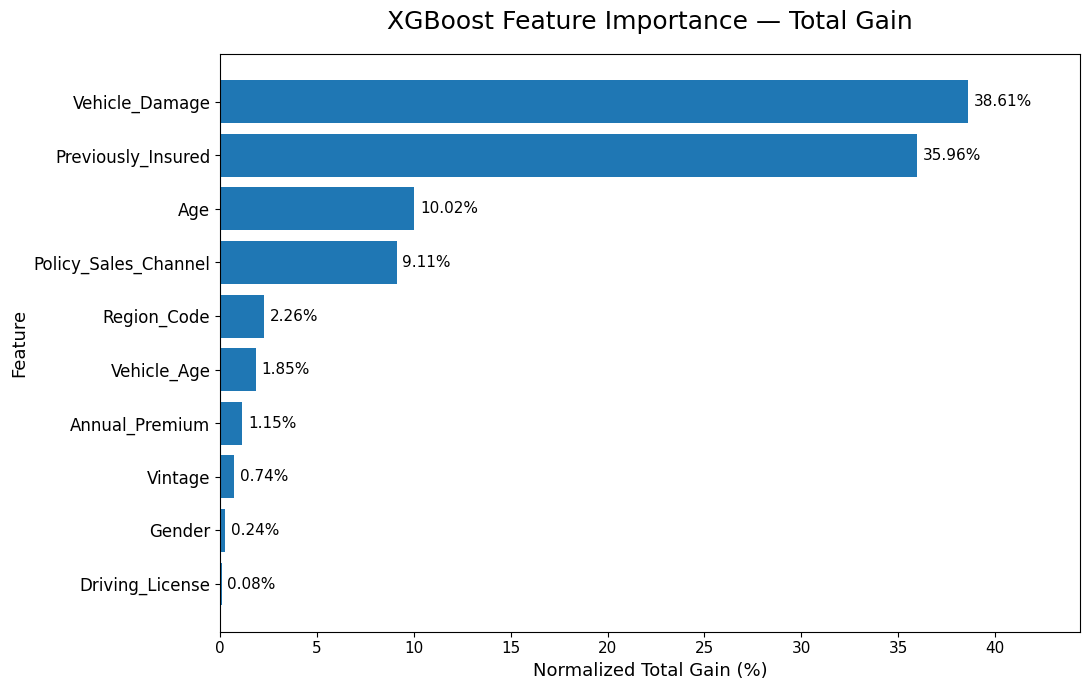

In [27]:
import matplotlib.pyplot as plt


plot_df = (
    original_importance_df
    .sort_values(
        "importance_pct",
        ascending=True
    )
)


plt.figure(
    figsize=(11, 7)
)


bars = plt.barh(
    plot_df["original_feature"],
    plot_df["importance_pct"]
)


plt.title(
    "XGBoost Feature Importance — Total Gain",
    fontsize=18,
    pad=18
)


plt.xlabel(
    "Normalized Total Gain (%)",
    fontsize=13
)


plt.ylabel(
    "Feature",
    fontsize=13
)


plt.xticks(
    fontsize=11
)

plt.yticks(
    fontsize=12
)


for bar, value in zip(
    bars,
    plot_df["importance_pct"]
):

    plt.text(
        bar.get_width() + 0.3,
        bar.get_y()
        + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=11
    )


plt.xlim(
    0,
    plot_df[
        "importance_pct"
    ].max() * 1.15
)


plt.tight_layout()
plt.show()

In [19]:
from scipy.stats import pointbiserialr

cols = [
    "Annual_Premium",
    "Vintage",
    "Driving_License"
]

for col in cols:
    r, p = pointbiserialr(
        train["Response"],
        train[col]
    )

    print(f"{col}")
    print(f"  Point-Biserial r : {r:.6f}")
    print(f"  p-value          : {p:.10g}")

    if p < 0.05:
        print("  결과             : 통계적으로 유의함 (p < 0.05)")
    else:
        print("  결과             : 통계적으로 유의하지 않음 (p >= 0.05)")

    print()

Annual_Premium
  Point-Biserial r : 0.022575
  p-value          : 3.72231514e-44
  결과             : 통계적으로 유의함 (p < 0.05)

Vintage
  Point-Biserial r : -0.001050
  p-value          : 0.5167036523
  결과             : 통계적으로 유의하지 않음 (p >= 0.05)

Driving_License
  Point-Biserial r : 0.010155
  p-value          : 3.625834382e-10
  결과             : 통계적으로 유의함 (p < 0.05)



In [9]:
import pandas as pd
import numpy as np
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)


# ==============================
# 데이터 불러오기
# ==============================

train = pd.read_csv("train.csv")


# ==============================
# 기존과 동일한 Binary Encoding
# ==============================

train["Gender"] = train["Gender"].map({
    "Female": 0,
    "Male": 1
})

train["Vehicle_Damage"] = train["Vehicle_Damage"].map({
    "No": 0,
    "Yes": 1
})


# ==============================
# X / y
# ==============================

X = train.drop(
    columns=["id", "Response"]
).copy()

y = train["Response"].copy()


# ==============================
# Vintage 제거
# ==============================

X_no_vintage = X.drop(
    columns=["Vintage"]
)


print("기존 Feature 수 :", X.shape[1])
print("Vintage 제거 후 :", X_no_vintage.shape[1])

기존 Feature 수 : 10
Vintage 제거 후 : 9


In [10]:
production_model = joblib.load(
    "final_xgboost_model.pkl"
)

In [11]:
categorical_cols_nv = [
    "Region_Code",
    "Vehicle_Age",
    "Policy_Sales_Channel"
]

numeric_cols_nv = [
    "Age",
    "Annual_Premium"
]

binary_cols_nv = [
    "Gender",
    "Driving_License",
    "Previously_Insured",
    "Vehicle_Damage"
]


# 트리 모델용 전처리
preprocessor_no_vintage = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numeric_cols_nv
        ),
        (
            "binary",
            "passthrough",
            binary_cols_nv
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_cols_nv
        )
    ]
)


# 기존 최종 XGBoost의 하이퍼파라미터 그대로 복제
xgb_same_params = clone(
    production_model.named_steps["model"]
)


model_no_vintage = Pipeline([
    (
        "preprocessor",
        preprocessor_no_vintage
    ),
    (
        "model",
        xgb_same_params
    )
])


print(model_no_vintage)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['Age', 'Annual_Premium']),
                                                 ('binary', 'passthrough',
                                                  ['Gender', 'Driving_License',
                                                   'Previously_Insured',
                                                   'Vehicle_Damage']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Region_Code', 'Vehicle_Age',
                                                   'Policy_Sales_Channel'])])),
                ('model',
                 XGBClassifier(base_score=None, boost...
                               feature_types=None, gamma=0.1, gpu_id=None,
                               grow_policy=None, imp

In [12]:
X_train_nv, X_valid_nv, y_train_nv, y_valid_nv = train_test_split(
    X_no_vintage,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


print("Train:", X_train_nv.shape)
print("Valid:", X_valid_nv.shape)

print()
print("Train Response ratio:")
print(y_train_nv.value_counts(normalize=True))

print()
print("Valid Response ratio:")
print(y_valid_nv.value_counts(normalize=True))

Train: (304887, 9)
Valid: (76222, 9)

Train Response ratio:
0    0.877437
1    0.122563
Name: Response, dtype: float64

Valid Response ratio:
0    0.877437
1    0.122563
Name: Response, dtype: float64


In [13]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


oof_prob_nv = cross_val_predict(
    model_no_vintage,
    X_train_nv,
    y_train_nv,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]


precision_nv, recall_nv, thresholds_nv = (
    precision_recall_curve(
        y_train_nv,
        oof_prob_nv
    )
)


f1_scores_nv = (
    2
    * precision_nv[:-1]
    * recall_nv[:-1]
    /
    (
        precision_nv[:-1]
        + recall_nv[:-1]
        + 1e-10
    )
)


best_idx_nv = np.argmax(
    f1_scores_nv
)


best_threshold_nv = (
    thresholds_nv[
        best_idx_nv
    ]
)


print(
    "Vintage 제거 OOF Threshold:",
    best_threshold_nv
)

print(
    "Vintage 제거 OOF F1:",
    f1_scores_nv[
        best_idx_nv
    ]
)

print(
    "Vintage 제거 OOF ROC-AUC:",
    roc_auc_score(
        y_train_nv,
        oof_prob_nv
    )
)

print(
    "Vintage 제거 OOF AP:",
    average_precision_score(
        y_train_nv,
        oof_prob_nv
    )
)

Vintage 제거 OOF Threshold: 0.22261247
Vintage 제거 OOF F1: 0.45995055323332684
Vintage 제거 OOF ROC-AUC: 0.8583112149436551
Vintage 제거 OOF AP: 0.3710181449508707


In [14]:
model_no_vintage.fit(
    X_train_nv,
    y_train_nv
)


valid_prob_nv = (
    model_no_vintage
    .predict_proba(
        X_valid_nv
    )[:, 1]
)


valid_pred_nv = (
    valid_prob_nv
    >= best_threshold_nv
).astype(int)


results_no_vintage = {
    "Threshold":
        best_threshold_nv,

    "Precision":
        precision_score(
            y_valid_nv,
            valid_pred_nv
        ),

    "Recall":
        recall_score(
            y_valid_nv,
            valid_pred_nv
        ),

    "F1":
        f1_score(
            y_valid_nv,
            valid_pred_nv
        ),

    "ROC_AUC":
        roc_auc_score(
            y_valid_nv,
            valid_prob_nv
        ),

    "AP":
        average_precision_score(
            y_valid_nv,
            valid_prob_nv
        )
}


results_no_vintage

{'Threshold': 0.22261247,
 'Precision': 0.32849755159946914,
 'Recall': 0.7683579533290515,
 'F1': 0.4602314621870292,
 'ROC_AUC': 0.8587012576134021,
 'AP': 0.37213182732689376}

In [15]:
original_results = {
    "Threshold": 0.2285,
    "Precision": 0.3309770141847292,
    "Recall": 0.756797259687433,
    "F1": 0.46054131518092695,
    "ROC_AUC": 0.8586737717083113,
    "AP": 0.3716908143849149
}


comparison = pd.DataFrame({
    "Original_XGBoost": original_results,
    "Without_Vintage": results_no_vintage
})


comparison["Difference"] = (
    comparison["Without_Vintage"]
    - comparison["Original_XGBoost"]
)


display(
    comparison.round(6)
)

,Original_XGBoost,Without_Vintage,Difference
Threshold,0.228500,0.222612,-0.005888
Precision,0.330977,0.328498,-0.002479
Recall,0.756797,0.768358,0.011561
F1,0.460541,0.460231,-0.000310
ROC_AUC,0.858674,0.858701,0.000027
AP,0.371691,0.372132,0.000441


In [16]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Vintage 제거 모델의 validation probability
# valid_prob_nv 사용

targets = [0.80, 0.85, 0.90, 0.95]

rows = []

threshold_candidates = np.linspace(
    0.01,
    0.50,
    3000
)

for target_recall in targets:

    candidates = []

    for threshold in threshold_candidates:

        pred = (
            valid_prob_nv >= threshold
        ).astype(int)

        recall = recall_score(
            y_valid_nv,
            pred
        )

        if recall >= target_recall:

            precision = precision_score(
                y_valid_nv,
                pred
            )

            f1 = f1_score(
                y_valid_nv,
                pred
            )

            candidates.append({
                "Threshold": threshold,
                "Precision": precision,
                "Recall": recall,
                "F1": f1,
                "Predicted_Positive": pred.sum()
            })

    if candidates:

        # 목표 Recall을 만족하면서 Precision이 가장 높은 지점
        best = max(
            candidates,
            key=lambda x: x["Precision"]
        )

        rows.append({
            "Target Recall": target_recall,
            **best
        })


recall_comparison = pd.DataFrame(rows)

display(
    recall_comparison.round(4)
)

,Target Recall,Threshold,Precision,Recall,F1,Predicted_Positive
0,0.80,0.2087,0.3230,0.8000,0.4602,23141
1,0.85,0.1803,0.3109,0.8502,0.4554,25545
2,0.90,0.1471,0.2961,0.9000,0.4456,28392
3,0.95,0.0995,0.2747,0.9500,0.4261,32311


In [17]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# ============================================================
# 1. OOF 예측에서 목표 Recall별 Threshold 선택
# ============================================================

target_recalls = [0.80, 0.85, 0.90, 0.95]

precision_oof, recall_oof, thresholds_oof = precision_recall_curve(
    y_train_nv,
    oof_prob_nv
)

rows = []

for target in target_recalls:

    # thresholds와 길이를 맞추기 위해 마지막 precision/recall 제외
    p = precision_oof[:-1]
    r = recall_oof[:-1]
    t = thresholds_oof

    # 목표 Recall 이상인 지점
    mask = r >= target

    if not np.any(mask):
        continue

    candidate_idx = np.where(mask)[0]

    # 목표 Recall 이상 중 Precision이 가장 높은 지점
    best_idx = candidate_idx[
        np.argmax(p[candidate_idx])
    ]

    threshold = t[best_idx]

    # ========================================================
    # 2. 선택된 Threshold를 Validation에 그대로 적용
    # ========================================================

    valid_pred = (
        valid_prob_nv >= threshold
    ).astype(int)

    rows.append({
        "Target_Recall": target,
        "OOF_Threshold": threshold,
        "Valid_Precision": precision_score(
            y_valid_nv,
            valid_pred
        ),
        "Valid_Recall": recall_score(
            y_valid_nv,
            valid_pred
        ),
        "Valid_F1": f1_score(
            y_valid_nv,
            valid_pred
        ),
        "ROC_AUC": roc_auc_score(
            y_valid_nv,
            valid_prob_nv
        ),
        "AP": average_precision_score(
            y_valid_nv,
            valid_prob_nv
        ),
        "Predicted_Positive": valid_pred.sum()
    })


fair_recall_comparison = pd.DataFrame(rows)

display(
    fair_recall_comparison.round(4)
)


,Target_Recall,OOF_Threshold,Valid_Precision,Valid_Recall,Valid_F1,ROC_AUC,AP,Predicted_Positive
0,0.80,0.2068,0.3222,0.8034,0.4599,0.8587,0.3721,23296
1,0.85,0.1782,0.3099,0.8532,0.4546,0.8587,0.3721,25724
2,0.90,0.1455,0.2953,0.9012,0.4448,0.8587,0.3721,28512
3,0.95,0.0996,0.2747,0.9499,0.4262,0.8587,0.3721,32300
